# MD2 · Reglas de asociación
### H&M Personalized Fashion Recommendations · Grupo 2 · Minería de Datos · Semana 12

**Modalidad:** `COMPLETA` · **Salida:** dos ZIP (evidencias y modelos) + notebook ejecutado.

**Objetivo:** cestas cliente–día; reglas de coocurrencia. **Métodos:** Apriori y FP-Growth.

**Ruta de lectura:** planteamiento → entorno → datos → exploración → diseño → variables → modelado → evaluación visual → test → interpretación → persistencia → auditoría/ZIP → conclusiones.

> **Integridad:** las pruebas P01–P04 conservan sus criterios originales. Un proceso `OK` sin patrones no equivale a evidencia de minería. Las decisiones se toman antes de abrir el test; los modelos de despliegue se distinguen de los evaluados. Los `.joblib` y `.pkl` solo deben cargarse desde fuentes confiables.


## 1. Planteamiento y alcance

**Pregunta de investigación:** ¿Qué aporta Apriori y FP-Growth para cestas cliente–día; reglas de coocurrencia?  Los experimentos P01–P04 se ejecutan y se evalúan bajo las particiones y reglas del protocolo aprobado.


## 2. Entorno reproducible y configuración

**Modo `COMPLETA`:** instalación condicional, semilla, firma de entradas, cachés y trazabilidad. Las salidas se escriben en `/kaggle/working/hm_modelamiento`.


In [1]:
# Dependencias necesarias para MD-2 (solo CPU).
import importlib.util, subprocess, sys, os, time, warnings, tempfile
from pathlib import Path
warnings.filterwarnings('ignore',message=r'datetime\.datetime\.utcnow\(\) is deprecated.*',
                        category=DeprecationWarning,module=r'jupyter_client\.session')
DEPENDENCIAS=[('duckdb','duckdb==1.3.2'),('mlxtend','mlxtend>=0.23.0')]
missing=[pkg for module,pkg in DEPENDENCIAS if importlib.util.find_spec(module) is None]
if missing:
    print('[MD2 instalación] Dependencias faltantes:',missing,flush=True)
    tmp=Path(tempfile.gettempdir())/'md2_pip_instalacion.log'
    inicio=time.monotonic()
    with tmp.open('w',encoding='utf-8') as log:
        p=subprocess.Popen([sys.executable,'-m','pip','install',*missing],stdout=log,stderr=subprocess.STDOUT)
        try:
            while p.poll() is None:
                if time.monotonic()-inicio>600:
                    p.terminate()
                    try:p.wait(timeout=4)
                    except subprocess.TimeoutExpired:p.kill();p.wait()
                    raise TimeoutError('Instalación superó 10 min; revisar conectividad de Kaggle e instalar offline.')
                try:
                    p.wait(timeout=20)
                except subprocess.TimeoutExpired:
                    print(f'[MD2 instalación] En curso: {time.monotonic()-inicio:.0f}s',flush=True)
        except KeyboardInterrupt:
            if p.poll() is None:p.terminate();p.wait(timeout=10)
            raise
    if p.returncode!=0:
        raise RuntimeError(f'Falló pip (código {p.returncode}). Últimas líneas:\n'+tmp.read_text(errors='replace')[-2000:])
    print(f'[MD2 instalación] OK en {time.monotonic()-inicio:.1f}s',flush=True)
else:
    print('[MD2 instalación] Dependencias ya disponibles.',flush=True)


[MD2 instalación] Dependencias ya disponibles.


In [2]:
# Configuración portable: Kaggle primero, pero sin asumir rutas fijas.
from pathlib import Path
import os, json, time, platform, hashlib, warnings, sys
import numpy as np, pandas as pd
from packaging.version import Version
from importlib.metadata import version, PackageNotFoundError
import psutil
DATA_FILENAMES = {'transactions':'transacciones_preparadas.parquet',
                  'customers':'clientes_preparados.parquet',
                  'segmentation':'clientes_vista_segmentacion.parquet',
                  'articles':'articles_preparado.parquet'}
KAGGLE_CANDIDATE = Path('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados')
INPUT_DIR = Path(os.environ.get('HM_INPUT_DIR', str(KAGGLE_CANDIDATE)))
if not all((INPUT_DIR / x).is_file() for x in DATA_FILENAMES.values()):
    roots=[Path('/kaggle/input'), Path.cwd(), Path('/mnt/data')]
    found=[]
    for root in roots:
        if root.is_dir():
            for path in root.rglob('transacciones_preparadas.parquet'):
                if all((path.parent / fn).is_file() for fn in DATA_FILENAMES.values()): found.append(path.parent.resolve())
    found=list(dict.fromkeys(found))
    if len(found)!=1: raise FileNotFoundError(f'Esperado un único directorio con los cuatro Parquet. Encontrados: {found}. Defina HM_INPUT_DIR.')
    INPUT_DIR=found[0]
FILES={k:INPUT_DIR / v for k,v in DATA_FILENAMES.items()}
OUTPUT_ROOT=Path(os.environ.get('HM_OUTPUT_DIR','/kaggle/working/hm_modelamiento' if Path('/kaggle/working').is_dir() else str(Path.cwd()/'hm_modelamiento')))
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
print('Datos:',INPUT_DIR,'RAM disponible GiB:',round(psutil.virtual_memory().available/2**30,2))
print('CPU lógicas:',os.cpu_count(),'Python:',sys.version.split()[0])
print({k:(str(v), round(v.stat().st_size/2**20,1)) for k,v in FILES.items()})
def _has_pkg(n):
    try:version(n);return True
    except PackageNotFoundError:return False
try:
    import duckdb
except ImportError as exc:
    raise RuntimeError('Falta duckdb. En Kaggle: habilitar instalación si es necesaria y ejecutar %pip install duckdb==1.3.2') from exc
con=duckdb.connect(database=':memory:')
con.execute('PRAGMA threads=4')
con.execute("SET memory_limit='8GB'")
PTRANS=str(FILES['transactions']).replace("'", "''")
PART=str(FILES['articles']).replace("'", "''")
PCUST=str(FILES['customers']).replace("'", "''")
PSEG=str(FILES['segmentation']).replace("'", "''")

OUT=OUTPUT_ROOT/'md2';OUT.mkdir(parents=True,exist_ok=True)
def save_csv(df, filename):
    p=OUT/filename; p.parent.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(df).to_csv(p,index=False); print('Guardado:',p); return p

def save_json(obj, filename):
    p=OUT/filename; p.parent.mkdir(parents=True,exist_ok=True)
    p.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
    print('Guardado:',p);return p

def sha256_path(path):
    h=hashlib.sha256()
    tam=path.stat().st_size; procesados=0; inicio=time.monotonic();siguiente=128*2**20
    print(f'[MD2 SHA] {path.name}: {tam/2**20:.1f} MiB',flush=True)
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''):
            h.update(b);procesados+=len(b)
            if procesados>=siguiente:
                print(f'[MD2 SHA] {path.name}: {procesados/tam:.0%} en {time.monotonic()-inicio:.1f}s',flush=True)
                siguiente+=128*2**20
    return h.hexdigest()

SOURCE={'sha256':{k:sha256_path(v) for k,v in FILES.items()},'runtime':platform.platform(),'python':sys.version.split()[0],
        'packages':{n:(version(n) if _has_pkg(n) else None) for n in ['numpy','pandas','scikit-learn','statsmodels','duckdb']}}
save_json(SOURCE,'entrada_y_entorno.json')
STATUS=[]
def registro(prueba,etapa,estado,detalle='',duracion_s=None):
    item={'prueba':prueba,'etapa':etapa,'estado':estado,'detalle':str(detalle),'duracion_s':duracion_s}
    STATUS.append(item)
    save_csv(STATUS,'estado_experimentos.csv')
    return item


Datos: /kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados RAM disponible GiB: 30.01
CPU lógicas: 4 Python: 3.13.18
{'transactions': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/transacciones_preparadas.parquet', 448.3), 'customers': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/clientes_preparados.parquet', 160.2), 'segmentation': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/clientes_vista_segmentacion.parquet', 80.4), 'articles': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/articles_preparado.parquet', 16.9)}
[MD2 SHA] transacciones_preparadas.parquet: 448.3 MiB
[MD2 SHA] transacciones_preparadas.parquet: 29% en 0.9s
[MD2 SHA] transacciones_preparadas.parquet: 57% en 1.7s
[MD2 SHA] transacciones_preparadas.parquet: 86% en 2.4s
[MD2 SHA] clientes_preparados.parquet: 160.2 MiB
[MD2 SHA] clientes_preparados.parquet: 80% en 1.0s
[MD2 SHA] clientes_vista_segmentacion.parquet: 80.4 MiB
[MD2 SHA] 

In [3]:

# Cache cannot be silently reused with a different set of input files.
INPUT_SIGNATURE = SOURCE['sha256']
p_input = OUT / 'origen_cache.json'
if p_input.exists():
    old = json.loads(p_input.read_text(encoding='utf-8'))
    if old.get('sha256') != INPUT_SIGNATURE:
        raise RuntimeError('El origen cambió respecto a los cachés previos. Usar un nuevo HM_OUTPUT_DIR o depurar cachés de forma controlada.')
else:
    p_input.write_text(json.dumps({'sha256':INPUT_SIGNATURE},indent=2),encoding='utf-8')


In [4]:
# MD-2 — Monitoreo transversal (Kaggle CPU)
# No corta consultas DuckDB desde un hilo: sus límites de tiempo son advertencias.
# Solo los mineros ejecutados en procesos independientes tienen timeout duro.
from contextlib import contextmanager
from datetime import datetime, timezone
import os, time, threading, warnings, traceback, psutil, json
from pathlib import Path
import pandas as pd

warnings.filterwarnings('ignore', message=r'datetime\.datetime\.utcnow\(\) is deprecated.*',
                        category=DeprecationWarning, module=r'jupyter_client\.session')
MD2_HEARTBEAT_S = 20  # un mensaje por cada 20 s por operación larga
MD2_PROCESS = psutil.Process(os.getpid())
MD2_LOG_PATH = OUT / 'md2_bitacora_pasos.csv'

def md2_atomic_csv(datos, nombre):
    """Evita dejar un CSV parcialmente escrito si se interrumpe una celda."""
    destino = OUT / nombre
    destino.parent.mkdir(parents=True, exist_ok=True)
    temporal = destino.with_name(destino.name + '.en_escritura')
    try:
        pd.DataFrame(datos).to_csv(temporal, index=False)
        os.replace(temporal, destino)
    finally:
        temporal.unlink(missing_ok=True)
    return destino

# Sobrescribir la utilidad inicial: conserva su interfaz y mejora su atomicidad.
def save_csv(df, filename):
    destino = md2_atomic_csv(df, filename)
    print('Guardado:', destino, flush=True)
    return destino

def save_json(obj, filename):
    destino=OUT/filename
    destino.parent.mkdir(parents=True,exist_ok=True)
    temporal=destino.with_name(destino.name+'.en_escritura')
    try:
        temporal.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
        os.replace(temporal,destino)
    finally:
        temporal.unlink(missing_ok=True)
    print('Guardado:',destino,flush=True)
    return destino

def md2_evento(nombre,estado,duracion_s=None,detalle=''):
    fila={'timestamp_utc':datetime.now(timezone.utc).isoformat(),
          'paso':str(nombre),'estado':str(estado),
          'duracion_s':None if duracion_s is None else round(float(duracion_s),2),
          'rss_gib':round(MD2_PROCESS.memory_info().rss/2**30,3),
          'ram_disponible_gib':round(psutil.virtual_memory().available/2**30,3),
          'detalle':str(detalle)[:700]}
    try:
        anterior=(pd.read_csv(MD2_LOG_PATH).to_dict('records')
                  if MD2_LOG_PATH.exists() and MD2_LOG_PATH.stat().st_size>5 else [])
        md2_atomic_csv(anterior+[fila],MD2_LOG_PATH.name)
    except Exception as err:
        print('[MD2] No se pudo persistir la bitácora:',repr(err),flush=True)
    return fila

@contextmanager
def md2_paso(nombre, aviso_segundos=None):
    """Progreso y RSS mientras Python/DuckDB trabajan; no modifica el cálculo."""
    inicio=time.monotonic();paro=threading.Event();nombre=str(nombre)
    print(f'\n[MD2 ►] {nombre} | inicio {datetime.now(timezone.utc).isoformat()}',flush=True)
    md2_evento(nombre,'INICIADO')
    def heartbeat():
        advertido=False
        while not paro.wait(MD2_HEARTBEAT_S):
            transcurrido=time.monotonic()-inicio
            rss=MD2_PROCESS.memory_info().rss/2**30
            disponible=psutil.virtual_memory().available/2**30
            print(f'[MD2 …] {nombre} | {transcurrido:.0f}s | RSS {rss:.2f} GiB | RAM libre {disponible:.2f} GiB',flush=True)
            if aviso_segundos and not advertido and transcurrido>=aviso_segundos:
                print(f'[MD2 !] {nombre}: superó {aviso_segundos}s. Aviso, NO timeout; la operación continúa.',flush=True)
                advertido=True
    hilo=threading.Thread(target=heartbeat,name='md2-progreso',daemon=True)
    hilo.start();estado='OK';detalle=''
    try:
        yield
    except BaseException as err:
        estado='INTERRUMPIDO' if isinstance(err,KeyboardInterrupt) else 'ERROR'
        detalle=f'{type(err).__name__}: {err}'
        raise
    finally:
        paro.set();hilo.join(timeout=1)
        duracion=time.monotonic()-inicio
        md2_evento(nombre,estado,duracion,detalle)
        print(f'[MD2 ■] {nombre} | {estado} | {duracion:.1f}s | RSS {MD2_PROCESS.memory_info().rss/2**30:.2f} GiB',flush=True)

print('Monitor activo. Intervalo:',MD2_HEARTBEAT_S,'s. Evidencia:',MD2_LOG_PATH)


Monitor activo. Intervalo: 20 s. Evidencia: /kaggle/working/hm_modelamiento/md2/md2_bitacora_pasos.csv


## 3. Carga y validación de datos

Validar las fuentes reales. No sustituir errores de entrada por muestras sintéticas.


In [5]:
from scipy.sparse import coo_matrix, csr_matrix
from collections import defaultdict
from itertools import combinations
import math
try:
    from mlxtend.frequent_patterns import fpgrowth, apriori, association_rules
except ImportError as exc:
    raise RuntimeError('Falta mlxtend. Habilitar Internet para instalación o adjuntar la biblioteca.') from exc

DEV_LAST='2020-06-30'; TEST_FIRST='2020-07-01'
CACHED=OUT/'incidencia'; CACHED.mkdir(exist_ok=True)
# Fracciones anidadas de clientes por hash DuckDB (mod 100000), sin materializar la fuente completa.

def _md2_parquet_correcto(path):
    if not path.is_file():return False
    try:
        con.execute(f'SELECT 1 FROM read_parquet({sql_literal_md2(str(path))}) LIMIT 1').fetchall()
        return True
    except Exception:
        return False

def sql_literal_md2(value):
    return "'"+str(value).replace("'","''")+"'"

def _md2_copy_atomic(sql, destino, nombre):
    parcial=destino.with_name(destino.stem+'.parcial.parquet')
    parcial.unlink(missing_ok=True)
    try:
        with md2_paso(nombre,aviso_segundos=180):
            con.execute(f'COPY ({sql}) TO {sql_literal_md2(str(parcial))} (FORMAT PARQUET)')
        if not _md2_parquet_correcto(parcial):
            raise RuntimeError('DuckDB no escribió un Parquet válido: '+str(parcial))
        os.replace(parcial,destino)
    finally:
        parcial.unlink(missing_ok=True)


def baskets(granularity='product_type_name',part='dev',fraction=0.01,weekly=False):
    assert granularity in ('product_type_name','article_id')
    assert part in ('dev','test')
    if part=='dev' and not (0<fraction<=1):raise ValueError('Fracción de clientes fuera de (0,1]')
    frac='all' if part=='test' else f'{fraction:.6f}'
    basename=f'{part}_{granularity}_{"semana" if weekly else "dia"}_{frac}'
    fhead=CACHED/(basename+'_cabeceras.parquet');flines=CACHED/(basename+'_lineas.parquet')
    period=f"t.t_dat <= DATE '{DEV_LAST}'" if part=='dev' else f"t.t_dat >= DATE '{TEST_FIRST}'"
    select_client=f'AND hash(t.customer_id) % 100000 < {int(fraction*100000)}' if part=='dev' else ''
    daycol="DATE_TRUNC('week',t.t_dat)::DATE" if weekly else 't.t_dat::DATE'
    if not _md2_parquet_correcto(fhead):
        sql=f'''SELECT DISTINCT t.customer_id, {daycol} AS fecha
            FROM read_parquet('{PTRANS}') t WHERE {period} {select_client}'''
        _md2_copy_atomic(sql,fhead,f'{basename} | preparar cabeceras')
    else:print('[MD2 caché] Cabeceras válidas:',fhead.name,flush=True)
    if not _md2_parquet_correcto(flines):
        itemcol='t.article_id' if granularity=='article_id' else 'a.product_type_name'
        join='' if granularity=='article_id' else f"JOIN read_parquet('{PART}') a ON t.article_id = a.article_id"
        sql=f'''SELECT DISTINCT t.customer_id, {daycol} AS fecha, {itemcol}::VARCHAR AS item
            FROM read_parquet('{PTRANS}') t {join} WHERE {period} {select_client}'''
        _md2_copy_atomic(sql,flines,f'{basename} | preparar líneas únicas')
    else:print('[MD2 caché] Líneas válidas:',flines.name,flush=True)
    with md2_paso(f'{basename} | cargar Parquet a pandas',aviso_segundos=120):
        heads=con.execute(f'SELECT * FROM read_parquet({sql_literal_md2(str(fhead))}) ORDER BY customer_id,fecha').df()
        lines=con.execute(f'SELECT * FROM read_parquet({sql_literal_md2(str(flines))}) ORDER BY customer_id,fecha,item').df()
        assert not heads.duplicated(['customer_id','fecha']).any()
        assert not lines.duplicated(['customer_id','fecha','item']).any()
    print(f'[MD2 cestas] {basename}: {len(heads):,} cestas, {len(lines):,} presencias',flush=True)
    return heads,lines

def build_incidence(heads,lines,min_frequency=None,required=None):
    with md2_paso(f'Incidencia dispersa N={len(heads):,}, líneas={len(lines):,}',aviso_segundos=120):
        idx=pd.MultiIndex.from_frame(heads[['customer_id','fecha']])
        li=pd.MultiIndex.from_frame(lines[['customer_id','fecha']])
        rows=idx.get_indexer(li)
        if (rows<0).any():raise AssertionError('Línea sin cabecera')
        freq=lines['item'].value_counts()
        selected=set(required) if required is not None else (set(freq.index) if min_frequency is None else set(freq[freq>=min_frequency].index))
        mask=lines['item'].isin(selected).to_numpy()
        cols=sorted(selected);index={it:i for i,it in enumerate(cols)}
        c=np.array([index[it] for it in lines.loc[mask,'item']],dtype=np.int32)
        mat=coo_matrix((np.ones(mask.sum(),dtype=np.bool_), (rows[mask],c)),shape=(len(heads),len(cols))).tocsr()
        mat.sum_duplicates();mat.data[:]=1
        frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))
        meta={'N':len(heads),'vacias':int(np.sum(mat.getnnz(axis=1)==0)),
              'items':len(cols),'cobertura':float(mask.mean()) if len(lines) else 0}
    print(f'[MD2 incidencia] N={meta["N"]:,}, ítems={meta["items"]:,}, vacías={meta["vacias"]:,}',flush=True)
    return mat,frame,meta

HEAD_PILOT,LINE_PILOT=baskets('product_type_name','dev',.001)
print('Piloto categorías 0,1 %:',len(HEAD_PILOT),'cestas',len(LINE_PILOT),'líneas',flush=True)
registro('MD2-P01','preparacion','PASS','Cestas por cliente-fecha sin duplicados')



[MD2 ►] dev_product_type_name_dia_0.001000 | preparar cabeceras | inicio 2026-11-10T18:55:40.358124+00:00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

[MD2 ■] dev_product_type_name_dia_0.001000 | preparar cabeceras | OK | 1.3s | RSS 0.35 GiB

[MD2 ►] dev_product_type_name_dia_0.001000 | preparar líneas únicas | inicio 2026-11-10T18:55:41.707654+00:00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

[MD2 ■] dev_product_type_name_dia_0.001000 | preparar líneas únicas | OK | 1.9s | RSS 0.33 GiB

[MD2 ►] dev_product_type_name_dia_0.001000 | cargar Parquet a pandas | inicio 2026-11-10T18:55:43.574300+00:00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[MD2 ■] dev_product_type_name_dia_0.001000 | cargar Parquet a pandas | OK | 0.1s | RSS 0.33 GiB
[MD2 cestas] dev_product_type_name_dia_0.001000: 8,321 cestas, 18,369 presencias
Piloto categorías 0,1 %: 8321 cestas 18369 líneas
Guardado: /kaggle/working/hm_modelamiento/md2/estado_experimentos.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

{'prueba': 'MD2-P01',
 'etapa': 'preparacion',
 'estado': 'PASS',
 'detalle': 'Cestas por cliente-fecha sin duplicados',
 'duracion_s': None}

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 4. Exploración orientada al modelado

**Lectura:** examina distribuciones y cobertura antes de ajustar, sin imprimir identificadores individuales.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Categorías más frecuentes en las cestas piloto**

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,presencias
item,
Trousers,2115
Sweater,1744
Dress,1556
T-shirt,1157
Top,980
Blouse,879
Bra,747
Vest top,730
Skirt,594


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

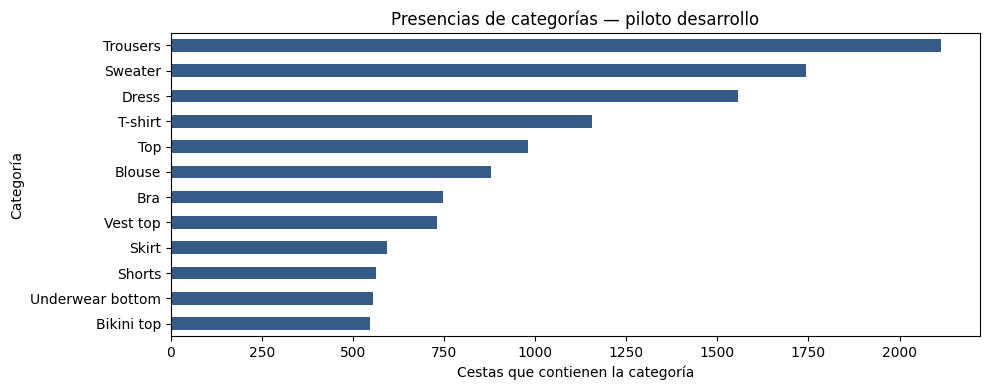

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [6]:
# Exploración: incidencia de cestas por categoría, sin exponer clientes.
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
_n=LINE_PILOT['item'].value_counts().head(12)
display(Markdown('**Categorías más frecuentes en las cestas piloto**'))
display(_n.rename('presencias').to_frame())
fig,ax=plt.subplots(figsize=(10,4));_n.iloc[::-1].plot.barh(ax=ax,color='#365b88')
ax.set(title='Presencias de categorías — piloto desarrollo',xlabel='Cestas que contienen la categoría',ylabel='Categoría')
fig.tight_layout();fig.savefig(OUT/'md2_exploracion_cestas.png',dpi=135);plt.show();plt.close(fig)


## 5. Diseño experimental y criterios de evaluación

**Métodos:** Apriori y FP-Growth. **Pruebas:** MD2-P01 a MD2-P04. La selección se decide con desarrollo/validación; test solo evalúa. Los estados incompletos se reportan, nunca se sustituyen por métricas ficticias.


## 6. Preparación de variables, matrices y particiones

Transformaciones reproducibles y particiones congeladas antes de evaluación retenida.


Se prepararon cestas únicas cliente–día en el capítulo 3. Se mantienen esas mismas definiciones y denominadores en las comparaciones.

## 7. Modelamiento y selección

Se ejecuta el protocolo completo, con guardado progresivo. Las técnicas no admiten resultados inventados en caso de timeout.


In [7]:
# MD-2 · Reemplazo COMPLETO de la primera celda del capítulo 4.
# Ejecutar tras capítulo 3 (baskets, build_incidence, OUT y registro definidos).
# Evita fork de un kernel Jupyter, registra progreso y guarda cada piloto.

import os
import sys
import json
import time
import warnings
import psutil
import tempfile
import subprocess
import textwrap
from pathlib import Path

warnings.filterwarnings(
    'ignore',
    message=r'datetime\.datetime\.utcnow\(\) is deprecated.*',
    category=DeprecationWarning,
    module=r'jupyter_client\.session',
)

# Mantener el máximo metodológico del documento: 20 min por corrida.
# Si deseas una prueba operacional corta, usa 300 en esta variable SOLO para
# diagnóstico y marca los TIMEOUT como pilotos inconclusos, no como inviabilidad definitiva.
PILOT_TIMEOUT_S = 1200
RAM_START = psutil.virtual_memory().available
MEM_CAP = int(0.80 * RAM_START)
print(f'MD-2 | Python aislado | timeout {PILOT_TIMEOUT_S}s/piloto | RAM inicial {RAM_START / 2**30:.2f} GiB', flush=True)

# El worker se ejecuta con un nuevo intérprete: NO hereda los hilos del kernel.
MD2_WORKER_SOURCE = r'''
import json, sys, time, traceback
from pathlib import Path
import pandas as pd
from mlxtend.frequent_patterns import fpgrowth, apriori

source, result, report, algorithm, threshold = sys.argv[1:]
start = time.monotonic()
try:
    frame = pd.read_pickle(source)
    fn = fpgrowth if algorithm == 'fpgrowth' else apriori
    frequent = fn(frame, min_support=float(threshold), use_colnames=True, max_len=3)
    frequent.to_pickle(result)
    status = {'estado':'OK', 'itemsets_n':int(len(frequent)), 'segundos':time.monotonic()-start}
except BaseException as exc:
    status = {'estado':'ERROR','error':repr(exc), 'traceback':traceback.format_exc()[-3500:],
              'segundos':time.monotonic()-start}
Path(report).write_text(json.dumps(status,ensure_ascii=False),encoding='utf-8')
'''

def miner_safe(fr, algorithm, support, sec=1200):
    """Mina itemsets aislado, con timeout, seguimiento de RAM y estado explícito.

    Mantiene la firma y las claves esperadas por los capítulos posteriores.
    """
    assert algorithm in {'fpgrowth','apriori'}, algorithm
    assert 0 < float(support) <= 1, support
    start = time.monotonic()
    with tempfile.TemporaryDirectory(prefix='md2_piloto_',dir=str(OUT)) as tmp:
        folder = Path(tmp)
        source, result, report, worker, log = (
            folder/'incidencia.pkl', folder/'itemsets.pkl',
            folder/'estado.json', folder/'worker.py', folder/'worker.log')
        worker.write_text(MD2_WORKER_SOURCE, encoding='utf-8')
        print(f'  [Preparando] {algorithm}, soporte={float(support):.8g}, N={len(fr):,}, ítems={fr.shape[1]:,}', flush=True)
        with md2_paso(f'{algorithm} | serializar incidencia para proceso aislado',aviso_segundos=60):
            fr.to_pickle(source)
        env = os.environ.copy()
        for key in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS'):
            env[key] = '2'
        peak = 0
        reason = None
        last_report = time.monotonic()
        with log.open('w',encoding='utf-8') as out:
            process = subprocess.Popen(
                [sys.executable, '-u', str(worker), str(source), str(result), str(report), algorithm, str(float(support))],
                cwd=str(folder), stdout=out, stderr=subprocess.STDOUT, env=env,
            )
            try:
                while process.poll() is None:
                    now = time.monotonic()
                    try:
                        parent = psutil.Process(process.pid)
                        family = [parent] + parent.children(recursive=True)
                        rss = sum(p.memory_info().rss for p in family if p.is_running())
                        peak = max(peak, rss)
                        if rss > MEM_CAP:
                            reason = 'MEMORIA'
                            break
                        if psutil.virtual_memory().available < max(1 * 2**30, int(0.20 * RAM_START)):
                            reason = 'MEMORIA_SISTEMA'
                            break
                    except (psutil.NoSuchProcess, psutil.AccessDenied):
                        pass
                    elapsed = now-start
                    if elapsed > sec:
                        reason = 'TIMEOUT'
                        break
                    if now-last_report >= 30:
                        print(f'    [En curso] {algorithm}: {elapsed:.0f}s; pico RSS {peak/2**30:.2f} GiB',flush=True)
                        last_report = now
                    time.sleep(.5)
            finally:
                if process.poll() is None:
                    process.terminate()
                    try:process.wait(timeout=5)
                    except subprocess.TimeoutExpired:
                        process.kill(); process.wait(timeout=5)
        elapsed = time.monotonic()-start
        if reason:
            item = {'estado':reason, 'error':f'Proceso detenido: {reason} (límite {sec}s por corrida)'}
        elif report.exists():
            try:item = json.loads(report.read_text(encoding='utf-8'))
            except Exception as exc:item = {'estado':'ERROR','error':f'Informe ilegible: {exc}'}
        else:
            item = {'estado':'ERROR', 'error':f'No existe reporte del worker; código de salida {process.returncode}. Log: '+log.read_text(errors='replace')[-1500:]}
        item['rss_max_bytes'] = peak
        item['wall_s'] = elapsed
        if item.get('estado') == 'OK':
            if not result.is_file():
                item = {'estado':'ERROR','error':'El worker declaró OK pero no guardó itemsets',
                        'rss_max_bytes':peak,'wall_s':elapsed}
            else:
                with md2_paso(f'{algorithm} | cargar itemsets del worker',aviso_segundos=60):
                    item['itemsets'] = pd.read_pickle(result)
        print(f'  [Finalizado] {algorithm}: {item["estado"]}; {elapsed:.1f}s; pico RSS {peak/2**30:.2f} GiB',flush=True)
        if item.get('estado') != 'OK':
            print('  Detalle:', str(item.get('error',''))[:500], flush=True)
        return item

PILOTS=[]
def one_pilot(gran,frac):
    label = f'{gran} / {frac:.4%} clientes'
    print('\n[Piloto iniciado]', label,flush=True)
    t = time.monotonic()
    try:
        md2_evento(label,'INICIADO')
        h,l = baskets(gran,'dev',frac)
        N = len(h)
        if N == 0:raise ValueError('No hay cestas para esta muestra')
        sup = .0005 if gran == 'product_type_name' else .00005
        fmin = max(30, math.ceil(sup*N))
        mat,fr,meta = build_incidence(h,l,min_frequency=fmin)
        del mat
        res = miner_safe(fr,'fpgrowth', fmin/N, sec=PILOT_TIMEOUT_S)
        if res.get('estado')=='OK' and (len(res.get('itemsets',[]))==0 or meta.get('items',0)==0):
            res['estado']='SIN_PATRONES_ELEGIBLES'
            res['error']='El proceso terminó, pero no existen itemsets elegibles al umbral fijado'
        details = {'vista':gran,'fraccion_clientes':frac,'support':sup,'nmin':fmin,**meta,
                   **{k:v for k,v in res.items() if k != 'itemsets'}}
    except Exception as exc:
        res = {'estado':'ERROR','error':f'{type(exc).__name__}: {exc}','wall_s':time.monotonic()-t}
        details = {'vista':gran,'fraccion_clientes':frac,'estado':'ERROR','error':res['error'],
                   'wall_s':res['wall_s']}
        print('[Error piloto]', label, res['error'],flush=True)
    PILOTS.append(details)
    md2_evento(label,res['estado'],details.get('wall_s',time.monotonic()-t),details.get('error',''))
    save_csv(PILOTS,'md2_pilotos.csv')  # Guardado incremental incluso ante fallo.
    print('[Piloto registrado]',label, 'estado='+res['estado'],flush=True)
    return res

cat01 = one_pilot('product_type_name',.001)
cat1 = one_pilot('product_type_name',.01) if cat01['estado']=='OK' else {'estado':'OMITIDO'}
art01 = one_pilot('article_id',.001)
art001 = one_pilot('article_id',.0001) if art01['estado'] not in ('OK',) else {'estado':'NO_NECESARIO'}
registro('MD2-P01','pilotos',
         'PASS' if cat01['estado']=='OK' and (art01['estado']=='OK' or art001['estado']=='OK') else 'PARCIAL',
         str(PILOTS))
print('\n[Resumen pilotos]',{n:r['estado'] for n,r in [
    ('cat_0.1%',cat01),('cat_1%',cat1),('art_0.1%',art01),('art_0.01%',art001)]},flush=True)


MD-2 | Python aislado | timeout 1200s/piloto | RAM inicial 29.72 GiB

[Piloto iniciado] product_type_name / 0.1000% clientes


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

[MD2 caché] Cabeceras válidas: dev_product_type_name_dia_0.001000_cabeceras.parquet
[MD2 caché] Líneas válidas: dev_product_type_name_dia_0.001000_lineas.parquet

[MD2 ►] dev_product_type_name_dia_0.001000 | cargar Parquet a pandas | inicio 2026-11-10T18:55:44.270961+00:00
[MD2 ■] dev_product_type_name_dia_0.001000 | cargar Parquet a pandas | OK | 0.1s | RSS 0.24 GiB
[MD2 cestas] dev_product_type_name_dia_0.001000: 8,321 cestas, 18,369 presencias

[MD2 ►] Incidencia dispersa N=8,321, líneas=18,369 | inicio 2026-11-10T18:55:44.334538+00:00
[MD2 ■] Incidencia dispersa N=8,321, líneas=18,369 | OK | 0.0s | RSS 0.24 GiB
[MD2 incidencia] N=8,321, ítems=49, vacías=68
  [Preparando] fpgrowth, soporte=0.0036053359, N=8,321, ítems=49

[MD2 ►] fpgrowth | serializar incidencia para proceso aislado | inicio 2026-11-10T18:55:44.391238+00:00


/tmp/ipykernel_49/2477108731.py:81: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))


[MD2 ■] fpgrowth | serializar incidencia para proceso aislado | OK | 0.0s | RSS 0.24 GiB

[MD2 ►] fpgrowth | cargar itemsets del worker | inicio 2026-11-10T18:55:51.418120+00:00
[MD2 ■] fpgrowth | cargar itemsets del worker | OK | 0.0s | RSS 0.23 GiB
  [Finalizado] fpgrowth: OK; 7.0s; pico RSS 0.12 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_pilotos.csv
[Piloto registrado] product_type_name / 0.1000% clientes estado=OK

[Piloto iniciado] product_type_name / 1.0000% clientes

[MD2 ►] dev_product_type_name_dia_0.010000 | preparar cabeceras | inicio 2026-11-10T18:55:51.445799+00:00
[MD2 ■] dev_product_type_name_dia_0.010000 | preparar cabeceras | OK | 1.2s | RSS 0.38 GiB

[MD2 ►] dev_product_type_name_dia_0.010000 | preparar líneas únicas | inicio 2026-11-10T18:55:52.656747+00:00
[MD2 ■] dev_product_type_name_dia_0.010000 | preparar líneas únicas | OK | 1.9s | RSS 0.41 GiB

[MD2 ►] dev_product_type_name_dia_0.010000 | cargar Parquet a pandas | inicio 2026-11-10T18:55:54.567683+0

/tmp/ipykernel_49/2477108731.py:81: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))


    [En curso] fpgrowth: 30s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 60s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 90s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 120s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 150s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 180s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 210s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 240s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 271s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 301s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 331s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 361s; pico RSS 0.18 GiB

[MD2 ►] fpgrowth | cargar itemsets del worker | inicio 2026-11-10T19:02:25.880636+00:00
[MD2 ■] fpgrowth | cargar itemsets del worker | OK | 0.0s | RSS 0.27 GiB
  [Finalizado] fpgrowth: OK; 390.8s; pico RSS 0.18 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_pilotos.csv
[Piloto registrado] product_type_name / 1.0000% clientes estado=OK

[Piloto iniciado] article_id / 0.1000% clientes

[MD2 ►] dev_article

/tmp/ipykernel_49/2477108731.py:81: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))



[MD2 ►] fpgrowth | cargar itemsets del worker | inicio 2026-11-10T19:02:29.980235+00:00
[MD2 ■] fpgrowth | cargar itemsets del worker | OK | 0.0s | RSS 0.23 GiB
  [Finalizado] fpgrowth: OK; 1.0s; pico RSS 0.10 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_pilotos.csv
[Piloto registrado] article_id / 0.1000% clientes estado=SIN_PATRONES_ELEGIBLES

[Piloto iniciado] article_id / 0.0100% clientes

[MD2 ►] dev_article_id_dia_0.000100 | preparar cabeceras | inicio 2026-11-10T19:02:30.009446+00:00
[MD2 ■] dev_article_id_dia_0.000100 | preparar cabeceras | OK | 1.2s | RSS 0.36 GiB

[MD2 ►] dev_article_id_dia_0.000100 | preparar líneas únicas | inicio 2026-11-10T19:02:31.227864+00:00
[MD2 ■] dev_article_id_dia_0.000100 | preparar líneas únicas | OK | 1.7s | RSS 0.33 GiB

[MD2 ►] dev_article_id_dia_0.000100 | cargar Parquet a pandas | inicio 2026-11-10T19:02:32.948142+00:00
[MD2 ■] dev_article_id_dia_0.000100 | cargar Parquet a pandas | OK | 0.0s | RSS 0.33 GiB
[MD2 cestas] dev_article

/tmp/ipykernel_49/2477108731.py:81: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))



[MD2 ►] fpgrowth | cargar itemsets del worker | inicio 2026-11-10T19:02:34.010549+00:00
[MD2 ■] fpgrowth | cargar itemsets del worker | OK | 0.0s | RSS 0.23 GiB
  [Finalizado] fpgrowth: OK; 1.0s; pico RSS 0.10 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_pilotos.csv
[Piloto registrado] article_id / 0.0100% clientes estado=SIN_PATRONES_ELEGIBLES
Guardado: /kaggle/working/hm_modelamiento/md2/estado_experimentos.csv

[Resumen pilotos] {'cat_0.1%': 'OK', 'cat_1%': 'OK', 'art_0.1%': 'SIN_PATRONES_ELEGIBLES', 'art_0.01%': 'SIN_PATRONES_ELEGIBLES'}


In [8]:
# MD2-P01 — misma incidencia, mismos ítems, mismo soporte, dos algoritmos.
COMPARACION=[]; MAIN_RULES=pd.DataFrame()
globals().pop('MAIN_FI',None)  # Evita reutilizar resultados de una ejecución anterior fallida.
COMPARISON_FRACTION=.01 if cat1['estado']=='OK' else (.001 if cat01['estado']=='OK' else None)
if COMPARISON_FRACTION is not None:
    h,l=baskets('product_type_name','dev',COMPARISON_FRACTION);N=len(h)
    sup=.0005;fmin=max(30,math.ceil(sup*N))
    mat,frame,meta=build_incidence(h,l,min_frequency=fmin)
    print(f'[MD2 P01] Apriori vs FP-Growth: N={N:,}; K={frame.shape[1]:,}; soporte efectivo={fmin/N:.8f}',flush=True)
    a=miner_safe(frame,'apriori',fmin/N)
    # Piloto de categorías con 1% utiliza exactamente igual muestra/umbral: reutilizar FP sin repetir ~350s.
    b=cat1 if COMPARISON_FRACTION==.01 and cat1.get('estado')=='OK' and 'itemsets' in cat1 else (cat01 if COMPARISON_FRACTION==.001 and cat01.get('estado')=='OK' and 'itemsets' in cat01 else miner_safe(frame,'fpgrowth',fmin/N))
    print('[MD2 OPTIMIZACION] FP-Growth reutilizado del piloto' if b is cat1 or b is cat01 else '[MD2] FP ejecutado en comparación',flush=True)
    save_csv([{'algoritmo':alg,'estado':res['estado'],'wall_s':res.get('wall_s'),
              'rss_bytes':res.get('rss_max_bytes'),'N':N,'vacias':meta['vacias'],
              'itemsets':len(res['itemsets']) if res['estado']=='OK' else None}
              for alg,res in [('apriori',a),('fpgrowth',b)]], 'md2_comparacion_algoritmos_estado.csv')
    if a['estado']=='OK' and b['estado']=='OK':
        support_A={frozenset(row.itemsets):float(row.support) for row in a['itemsets'].itertuples()}
        support_B={frozenset(row.itemsets):float(row.support) for row in b['itemsets'].itertuples()}
        if set(support_A)!=set(support_B):
            registro('MD2-P01','concordancia','FALLO','Itemsets diferentes')
            raise AssertionError('FP-Growth y Apriori difieren bajo la misma incidencia')
        bad=[key for key in support_A if not np.isclose(support_A[key],support_B[key],atol=1e-12,rtol=1e-10)]
        save_csv([{'algoritmo':'Apriori_vs_FPGrowth','itemsets':len(support_A),
                   'discrepancias_soporte':len(bad),'N':N,'igualdad':len(bad)==0}],
                 'md2_concordancia_itemsets_soportes.csv')
        if bad:
            registro('MD2-P01','concordancia_soporte','FALLO',f'{len(bad)} itemsets')
            raise AssertionError('Diferencias de soporte en Apriori y FP-Growth')
        for alg,res in [('apriori',a),('fpgrowth',b)]:
            COMPARACION.append({'algoritmo':alg,'itemsets':len(res['itemsets']),
                'wall_s':res['wall_s'],'rss_bytes':res['rss_max_bytes'],'N':N,'vacias':meta['vacias'],
                'origen_medicion':'piloto_reutilizado' if alg=='fpgrowth' and (b is cat1 or b is cat01) else 'ejecucion_nueva'})
        MAIN_FI=b['itemsets']
        registro('MD2-P01','algoritmos','PASS',len(MAIN_FI))
    else:
        registro('MD2-P01','algoritmos','INCOMPLETO',f"Apriori={a['estado']}, FP={b['estado']}")
    save_csv(COMPARACION,'md2_comparacion_algoritmos.csv')
else:
    registro('MD2-P01','algoritmos','PENDIENTE','Ningún piloto de categorías viable')


[MD2 caché] Cabeceras válidas: dev_product_type_name_dia_0.010000_cabeceras.parquet
[MD2 caché] Líneas válidas: dev_product_type_name_dia_0.010000_lineas.parquet

[MD2 ►] dev_product_type_name_dia_0.010000 | cargar Parquet a pandas | inicio 2026-11-10T19:02:34.061500+00:00
[MD2 ■] dev_product_type_name_dia_0.010000 | cargar Parquet a pandas | OK | 0.4s | RSS 0.37 GiB
[MD2 cestas] dev_product_type_name_dia_0.010000: 81,660 cestas, 179,857 presencias

[MD2 ►] Incidencia dispersa N=81,660, líneas=179,857 | inicio 2026-11-10T19:02:34.502290+00:00
[MD2 ■] Incidencia dispersa N=81,660, líneas=179,857 | OK | 0.2s | RSS 0.37 GiB
[MD2 incidencia] N=81,660, ítems=76, vacías=85
[MD2 P01] Apriori vs FP-Growth: N=81,660; K=76; soporte efectivo=0.00050208
  [Preparando] apriori, soporte=0.0005020818, N=81,660, ítems=76

[MD2 ►] apriori | serializar incidencia para proceso aislado | inicio 2026-11-10T19:02:34.683749+00:00
[MD2 ■] apriori | serializar incidencia para proceso aislado | OK | 0.0s | RSS 

/tmp/ipykernel_49/2477108731.py:81: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))



[MD2 ►] apriori | cargar itemsets del worker | inicio 2026-11-10T19:02:45.720474+00:00
[MD2 ■] apriori | cargar itemsets del worker | OK | 0.0s | RSS 0.27 GiB
  [Finalizado] apriori: OK; 11.0s; pico RSS 2.53 GiB
[MD2 OPTIMIZACION] FP-Growth reutilizado del piloto
Guardado: /kaggle/working/hm_modelamiento/md2/md2_comparacion_algoritmos_estado.csv
Guardado: /kaggle/working/hm_modelamiento/md2/md2_concordancia_itemsets_soportes.csv
Guardado: /kaggle/working/hm_modelamiento/md2/estado_experimentos.csv
Guardado: /kaggle/working/hm_modelamiento/md2/md2_comparacion_algoritmos.csv


In [9]:
# MD2-P02 — Sensibilidad de soporte, confianza y piso, siempre sobre desarrollo.
def rules_from_fi(fi,N,threshold=.2,floor=30):
    if fi is None or fi.empty:return pd.DataFrame()
    with md2_paso(f"Generar reglas: {len(fi):,} itemsets, confianza={threshold}",aviso_segundos=90):
        rules=association_rules(fi,metric='confidence',min_threshold=threshold)
        if rules.empty:return rules
        rules=rules[(rules.antecedents.map(len)+rules.consequents.map(len)<=3)&
                    (rules.consequents.map(len)==1)].copy()
        rules['count_xy']=np.rint(rules.support*N).astype(int)
        rules=rules[(rules.count_xy>=floor)&(rules.lift>1)].copy()
        rules['ant']=rules.antecedents.map(lambda x:'|'.join(sorted(map(str,x))))
        rules['cons']=rules.consequents.map(lambda x:'|'.join(sorted(map(str,x))))
        return rules.sort_values(['lift','support','ant','cons'],ascending=[False,False,True,True],kind='stable')

SENS=[];SUPPORT_RULES={}
if COMPARISON_FRACTION is not None and 'MAIN_FI' in globals():
    for s in (.0005,.001,.005):
        support_count=max(30,math.ceil(s*N))
        if s==.0005 and support_count==fmin:
            print('[MD2 P02] Reutilizar FP-Growth de P01 para soporte 0.0005 (mismas filas/ítems/umbral).',flush=True)
            res={'estado':'OK','itemsets':MAIN_FI}
        else:
            # Propiedad de antimonotonía: con idénticas cestas y vocabulario,
            # los itemsets de soporte superior son un subconjunto exacto del basal.
            filtrados=MAIN_FI[MAIN_FI.support >= (support_count/N - 1e-12)].copy()
            res={'estado':'OK','itemsets':filtrados}
            print(f'[MD2 OPTIMIZACION] Soporte {s}: filtrar {len(filtrados)} itemsets sin remarcar FP-Growth',flush=True)
        rls=rules_from_fi(res.get('itemsets'),N,.4,support_count) if res['estado']=='OK' else pd.DataFrame()
        SUPPORT_RULES[s]=rls
        SENS.append({'familia':'soporte','valor':s,'estado':res['estado'],
             'n_reglas':len(rls),'jaccard20_vs_principal':np.nan,'jaccard50_vs_principal':np.nan})
        save_csv(SENS,'md2_sensibilidad_umbrales.csv')
        print(f'[MD2 P02] Soporte {s}: {res["estado"]}; {len(rls)} reglas',flush=True)
    for confidence in (.2,.4,.6):
        with md2_paso(f'P02 | reglas confidence={confidence}',aviso_segundos=90):
            rules=rules_from_fi(MAIN_FI,N,confidence,max(30,math.ceil(.0005*N)))
        SENS.append({'familia':'confianza','valor':confidence,'estado':'OK','n_reglas':len(rules),
                     'jaccard20_vs_principal':np.nan,'jaccard50_vs_principal':np.nan})
        save_csv(SENS,'md2_sensibilidad_umbrales.csv')
    print('[MD2 P02] Extracción permisiva para pisos 20/30/50 (timeout máximo por minero: 20 min).',flush=True)
    _,frame20,meta20=build_incidence(h,l,min_frequency=20)
    r20=miner_safe(frame20,'fpgrowth',20/max(1,N))
    for floor in (20,30,50):
        rls=rules_from_fi(r20.get('itemsets'),N,.2,max(floor,math.ceil(.0005*N))) if r20['estado']=='OK' else pd.DataFrame()
        SENS.append({'familia':'piso_absoluto','valor':floor,'estado':r20['estado'],
             'n_reglas':len(rls),'N':N,'vacias':meta20['vacias']})
        save_csv(SENS,'md2_sensibilidad_umbrales.csv')
    with md2_paso('P02 | fijar reglas en desarrollo',aviso_segundos=90):
        MAIN_RULES=rules_from_fi(MAIN_FI,N,.2,max(30,math.ceil(.0005*N)))
    if not MAIN_RULES.empty:
        save_csv(MAIN_RULES[['ant','cons','support','confidence','lift','count_xy']].copy(),
                 'md2_reglas_desarrollo_congeladas.csv')
    base20=set(zip(MAIN_RULES.head(20).ant,MAIN_RULES.head(20).cons))
    base50=set(zip(MAIN_RULES.head(50).ant,MAIN_RULES.head(50).cons))
    for rec in SENS:
        if rec['familia']=='confianza':
            rr=rules_from_fi(MAIN_FI,N,rec['valor'],max(30,math.ceil(.0005*N)))
        elif rec['familia']=='soporte':
            rr=SUPPORT_RULES.get(rec['valor'],pd.DataFrame())
            if rec['estado']!='OK':continue
        else:
            rr=rules_from_fi(r20.get('itemsets'),N,.2,max(int(rec['valor']),math.ceil(.0005*N))) if r20['estado']=='OK' else pd.DataFrame()
        aa=set(zip(rr.head(20).ant,rr.head(20).cons)) if not rr.empty else set()
        bb=set(zip(rr.head(50).ant,rr.head(50).cons)) if not rr.empty else set()
        rec['jaccard20_vs_principal']=len(aa&base20)/len(aa|base20) if aa or base20 else np.nan
        rec['jaccard50_vs_principal']=len(bb&base50)/len(bb|base50) if bb or base50 else np.nan
    save_csv(SENS,'md2_sensibilidad_umbrales.csv')
    registro('MD2-P02','umbrales','PASS' if all(x['estado']=='OK' for x in SENS) else 'PARCIAL',len(SENS))
else:
    registro('MD2-P02','umbrales','PENDIENTE','Extracción base no aprobada')


[MD2 P02] Reutilizar FP-Growth de P01 para soporte 0.0005 (mismas filas/ítems/umbral).

[MD2 ►] Generar reglas: 1,831 itemsets, confianza=0.4 | inicio 2026-11-10T19:02:45.799223+00:00
[MD2 ■] Generar reglas: 1,831 itemsets, confianza=0.4 | OK | 0.0s | RSS 0.27 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_sensibilidad_umbrales.csv
[MD2 P02] Soporte 0.0005: OK; 368 reglas
[MD2 OPTIMIZACION] Soporte 0.001: filtrar 998 itemsets sin remarcar FP-Growth

[MD2 ►] Generar reglas: 998 itemsets, confianza=0.4 | inicio 2026-11-10T19:02:45.845466+00:00
[MD2 ■] Generar reglas: 998 itemsets, confianza=0.4 | OK | 0.0s | RSS 0.27 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_sensibilidad_umbrales.csv
[MD2 P02] Soporte 0.001: OK; 191 reglas
[MD2 OPTIMIZACION] Soporte 0.005: filtrar 205 itemsets sin remarcar FP-Growth

[MD2 ►] Generar reglas: 205 itemsets, confianza=0.4 | inicio 2026-11-10T19:02:45.878611+00:00
[MD2 ■] Generar reglas: 205 itemsets, confianza=0.4 | OK | 0.0s | RSS 0.27 Gi

/tmp/ipykernel_49/2477108731.py:81: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))


    [En curso] fpgrowth: 30s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 60s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 90s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 120s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 150s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 180s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 210s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 240s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 271s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 301s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 331s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 361s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 391s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 421s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 451s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 481s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 511s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 541s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 571s; pico RSS 0.19 GiB
    [En curso] fpgrowth: 601s; pico RSS 0.19 GiB
    [En curso] fpgrowth

In [10]:
# MD2-P02/P03 — tres remuestreos y sensibilidad del universo de cestas.
STABILITY=[]
def rank_rules(df,k):
    if df is None or df.empty:return set()
    return set(zip(df.head(k).ant,df.head(k).cons))
def jaccard(a,b):
    return float(len(a&b)/len(a|b)) if (a or b) else np.nan

def profile_incidence(name,matrix,columns,subset_mask=None):
    with md2_paso(f"P03 | construir incidencia {name} (N={matrix.shape[0]:,})",aviso_segundos=90):
        mask=np.asarray(subset_mask,dtype=bool) if subset_mask is not None else np.ones(matrix.shape[0],dtype=bool)
        reduced=matrix[mask,:]
        return pd.DataFrame.sparse.from_spmatrix(reduced,columns=columns).astype(pd.SparseDtype('bool',False))

if not MAIN_RULES.empty:
    base20=rank_rules(MAIN_RULES,20);base50=rank_rules(MAIN_RULES,50)
    base_cust=np.sort(h.customer_id.unique());selected_support=max(30,math.ceil(.0005*N))/N
    universe=list(frame.columns)
    resampled_rank=[]
    for seed in (42,123,2026):
        with md2_paso(f'P02 | preparar remuestreo {seed}',aviso_segundos=120):
            chosen=set(np.random.default_rng(seed).choice(base_cust,size=int(.8*len(base_cust)),replace=False))
            hh=h[h.customer_id.isin(chosen)].copy();ll=l[l.customer_id.isin(chosen)].copy()
            nn=len(hh);_,ff,m=build_incidence(hh,ll,required=universe)
        res=miner_safe(ff,'fpgrowth',max(30,math.ceil(selected_support*nn))/nn)
        rls=rules_from_fi(res.get('itemsets'),nn,.2,max(30,math.ceil(selected_support*nn))) if res['estado']=='OK' else pd.DataFrame()
        ranks=(rank_rules(rls,20),rank_rules(rls,50))
        resampled_rank.append((res['estado'],ranks))
        STABILITY.append({'seed':seed,'estado':res['estado'],'N':nn,'vacias':m['vacias'],
            'items_fijados':len(universe),'jaccard20_vs_base':jaccard(base20,ranks[0]) if res['estado']=='OK' else np.nan,
            'jaccard50_vs_base':jaccard(base50,ranks[1]) if res['estado']=='OK' else np.nan})
        save_csv(STABILITY,'md2_estabilidad_remuestreos.csv')
        print(f'[MD2 P02] Remuestreo {seed}: {res["estado"]}; guardada evidencia.',flush=True)
    seeds=(42,123,2026)
    for i in range(len(resampled_rank)):
        for j in range(i+1,len(resampled_rank)):
            state1,r1=resampled_rank[i];state2,r2=resampled_rank[j]
            ok=(state1=='OK' and state2=='OK')
            STABILITY.append({'seed':f'{seeds[i]} vs {seeds[j]}',
                'estado':'COMPARACION_PARES' if ok else 'NO_EVALUABLE',
                'N':np.nan,'vacias':np.nan,'items_fijados':len(universe),
                'jaccard20_vs_base':jaccard(r1[0],r2[0]) if ok else np.nan,
                'jaccard50_vs_base':jaccard(r1[1],r2[1]) if ok else np.nan})
    save_csv(STABILITY,'md2_estabilidad_remuestreos.csv')
    registro('MD2-P02','remuestreo','PASS' if all(x['estado']=='OK' for x in STABILITY[:3]) else 'INCOMPLETO',len(STABILITY))
    hw,lw=baskets('product_type_name','dev',COMPARISON_FRACTION,weekly=True)
    _,fw,mw=build_incidence(hw,lw,required=universe)
    wr=miner_safe(fw,'fpgrowth',max(30,math.ceil(.0005*len(hw)))/len(hw))
    week_rules=rules_from_fi(wr.get('itemsets'),len(hw),.2,max(30,math.ceil(.0005*len(hw)))) if wr['estado']=='OK' else pd.DataFrame()
    with md2_paso('P03 | calcular densidad diaria',aviso_segundos=90):
        daily_matrix=frame.sparse.to_coo().tocsr()
        daily_nnz=daily_matrix.getnnz(axis=1)
    ROW_SENS=[]
    for label,rowmask in [('todas',np.ones(N,dtype=bool)),('sin_vacias',daily_nnz>0),
                           ('sin_unitarias_y_vacias',daily_nnz>=2)]:
        nsub=int(rowmask.sum())
        if nsub==0:
            ROW_SENS.append({'escenario':label,'estado':'SIN_CESTAS','N':0})
            save_csv(ROW_SENS,'md2_sensibilidad_cestas.csv');continue
        if label=='todas':
            print('[MD2 P03] Reutilizar minería principal para cestas completas.',flush=True)
            ran={'estado':'OK','itemsets':MAIN_FI}
        else:
            fsub=profile_incidence(label,daily_matrix,universe,rowmask)
            sup_abs=max(30,math.ceil(.0005*nsub))
            ran=miner_safe(fsub,'fpgrowth',sup_abs/nsub)
        sup_abs=max(30,math.ceil(.0005*nsub))
        rls=rules_from_fi(ran.get('itemsets'),nsub,.2,sup_abs) if ran['estado']=='OK' else pd.DataFrame()
        ROW_SENS.append({'escenario':label,'estado':ran['estado'],'N':nsub,
            'vacias_excluidas':int(N-nsub),'n_reglas':len(rls),
            'jaccard20_vs_base':jaccard(base20,rank_rules(rls,20)) if ran['estado']=='OK' else np.nan,
            'jaccard50_vs_base':jaccard(base50,rank_rules(rls,50)) if ran['estado']=='OK' else np.nan})
        save_csv(ROW_SENS,'md2_sensibilidad_cestas.csv')
        print(f'[MD2 P03] {label}: {ran["estado"]}, N={nsub:,}',flush=True)
    PERIODS={'desarrollo':('2018-09-20','2020-06-30'), 'test':('2020-07-01','2020-09-22')}
    WEEK_META=[]
    for pname,(first,last) in PERIODS.items():
        date_range=pd.date_range(first,last)
        iso_starts=date_range-pd.to_timedelta(date_range.weekday,unit='D')
        c=pd.Series(iso_starts).value_counts()
        WEEK_META.append({'particion':pname,'semanas':len(c),'semanas_parciales':int((c<7).sum()),
                         'dias_en_semanas_parciales':int(c.loc[c<7].sum())})
    save_csv(WEEK_META,'md2_semanas_iso_parciales.csv')
    save_csv(ROW_SENS+[{'escenario':'semana_iso_desarrollo','estado':wr['estado'],
       'N':len(hw),'vacias_excluidas':0,'n_reglas':len(week_rules),
       'jaccard20_vs_base':jaccard(base20,rank_rules(week_rules,20)) if wr['estado']=='OK' else np.nan,
       'jaccard50_vs_base':jaccard(base50,rank_rules(week_rules,50)) if wr['estado']=='OK' else np.nan}],
       'md2_sensibilidad_cestas.csv')
    registro('MD2-P03','cestas','PASS' if wr['estado']=='OK' and all(r['estado']=='OK' for r in ROW_SENS) else 'INCOMPLETO',
             f'diarias {N} vs. semanas {len(hw)}; fraction={COMPARISON_FRACTION}')
else:
    registro('MD2-P03','cestas','PENDIENTE','Faltan reglas congeladas')



[MD2 ►] P02 | preparar remuestreo 42 | inicio 2026-11-10T19:14:36.817359+00:00

[MD2 ►] Incidencia dispersa N=65,122, líneas=144,205 | inicio 2026-11-10T19:14:36.884857+00:00
[MD2 ■] Incidencia dispersa N=65,122, líneas=144,205 | OK | 0.1s | RSS 0.30 GiB
[MD2 incidencia] N=65,122, ítems=76, vacías=69
[MD2 ■] P02 | preparar remuestreo 42 | OK | 0.2s | RSS 0.30 GiB
  [Preparando] fpgrowth, soporte=0.00050674119, N=65,122, ítems=76

[MD2 ►] fpgrowth | serializar incidencia para proceso aislado | inicio 2026-11-10T19:14:37.039703+00:00
[MD2 ■] fpgrowth | serializar incidencia para proceso aislado | OK | 0.0s | RSS 0.30 GiB


/tmp/ipykernel_49/2477108731.py:81: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))


    [En curso] fpgrowth: 30s; pico RSS 0.16 GiB
    [En curso] fpgrowth: 60s; pico RSS 0.17 GiB
    [En curso] fpgrowth: 90s; pico RSS 0.17 GiB
    [En curso] fpgrowth: 120s; pico RSS 0.17 GiB
    [En curso] fpgrowth: 150s; pico RSS 0.17 GiB
    [En curso] fpgrowth: 180s; pico RSS 0.17 GiB
    [En curso] fpgrowth: 210s; pico RSS 0.17 GiB
    [En curso] fpgrowth: 240s; pico RSS 0.17 GiB
    [En curso] fpgrowth: 271s; pico RSS 0.17 GiB
    [En curso] fpgrowth: 301s; pico RSS 0.17 GiB

[MD2 ►] fpgrowth | cargar itemsets del worker | inicio 2026-11-10T19:19:56.697614+00:00
[MD2 ■] fpgrowth | cargar itemsets del worker | OK | 0.0s | RSS 0.30 GiB
  [Finalizado] fpgrowth: OK; 319.7s; pico RSS 0.17 GiB

[MD2 ►] Generar reglas: 1,863 itemsets, confianza=0.2 | inicio 2026-11-10T19:19:56.716249+00:00
[MD2 ■] Generar reglas: 1,863 itemsets, confianza=0.2 | OK | 0.0s | RSS 0.30 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_estabilidad_remuestreos.csv
[MD2 P02] Remuestreo 42: OK; guardada ev

/tmp/ipykernel_49/2477108731.py:81: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))


    [En curso] fpgrowth: 30s; pico RSS 0.16 GiB
    [En curso] fpgrowth: 60s; pico RSS 0.16 GiB
    [En curso] fpgrowth: 90s; pico RSS 0.16 GiB
    [En curso] fpgrowth: 120s; pico RSS 0.16 GiB
    [En curso] fpgrowth: 150s; pico RSS 0.16 GiB
    [En curso] fpgrowth: 180s; pico RSS 0.16 GiB
    [En curso] fpgrowth: 210s; pico RSS 0.16 GiB
    [En curso] fpgrowth: 241s; pico RSS 0.16 GiB
    [En curso] fpgrowth: 271s; pico RSS 0.16 GiB

[MD2 ►] fpgrowth | cargar itemsets del worker | inicio 2026-11-10T19:24:49.581171+00:00
[MD2 ■] fpgrowth | cargar itemsets del worker | OK | 0.0s | RSS 0.30 GiB
  [Finalizado] fpgrowth: OK; 292.6s; pico RSS 0.16 GiB

[MD2 ►] Generar reglas: 1,783 itemsets, confianza=0.2 | inicio 2026-11-10T19:24:49.600893+00:00
[MD2 ■] Generar reglas: 1,783 itemsets, confianza=0.2 | OK | 0.0s | RSS 0.30 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_estabilidad_remuestreos.csv
[MD2 P02] Remuestreo 123: OK; guardada evidencia.

[MD2 ►] P02 | preparar remuestreo 2026

/tmp/ipykernel_49/2477108731.py:81: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  frame=pd.DataFrame.sparse.from_spmatrix(mat,columns=cols).astype(pd.SparseDtype('bool',False))


... (5 outputs left out)

/tmp/ipykernel_49/3533194952.py:13: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  return pd.DataFrame.sparse.from_spmatrix(reduced,columns=columns).astype(pd.SparseDtype('bool',False))


    [En curso] fpgrowth: 30s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 60s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 90s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 120s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 150s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 180s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 210s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 241s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 271s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 301s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 331s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 361s; pico RSS 0.18 GiB

[MD2 ►] fpgrowth | cargar itemsets del worker | inicio 2026-11-10T19:43:58.160287+00:00
[MD2 ■] fpgrowth | cargar itemsets del worker | OK | 0.0s | RSS 0.34 GiB
  [Finalizado] fpgrowth: OK; 385.8s; pico RSS 0.18 GiB

[MD2 ►] Generar reglas: 1,831 itemsets, confianza=0.2 | inicio 2026-11-10T19:43:58.178910+00:00
[MD2 ■] Generar reglas: 1,831 itemsets, confianza=0.2 | OK | 0.0s | RSS 0.34 GiB
Guardado: /kaggle/wo

/tmp/ipykernel_49/3533194952.py:13: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  return pd.DataFrame.sparse.from_spmatrix(reduced,columns=columns).astype(pd.SparseDtype('bool',False))


    [En curso] fpgrowth: 30s; pico RSS 0.17 GiB
    [En curso] fpgrowth: 60s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 90s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 120s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 150s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 180s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 210s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 241s; pico RSS 0.18 GiB
    [En curso] fpgrowth: 271s; pico RSS 0.18 GiB

[MD2 ►] fpgrowth | cargar itemsets del worker | inicio 2026-11-10T19:48:42.348116+00:00
[MD2 ■] fpgrowth | cargar itemsets del worker | OK | 0.0s | RSS 0.34 GiB
  [Finalizado] fpgrowth: OK; 284.1s; pico RSS 0.18 GiB

[MD2 ►] Generar reglas: 2,307 itemsets, confianza=0.2 | inicio 2026-11-10T19:48:42.365720+00:00
[MD2 ■] Generar reglas: 2,307 itemsets, confianza=0.2 | OK | 0.0s | RSS 0.34 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_sensibilidad_cestas.csv
[MD2 P03] sin_unitarias_y_vacias: OK, N=46,039
Guardado: /kaggle/working/hm_modelamiento/md2/

In [11]:
# MD2-P04 — prueba temporal sin reextraer reglas en test.
# Optimizacion: todos los X/Y se cuentan en UN escaneo por archivo Parquet,
# en lugar de abrir el Parquet 2 veces por regla. Se preserva N_test completo.
TEST_RULES=[];P99_REPORT=[]

def sql_literal(x):return "'"+str(x).replace("'","''")+"'"

def count_frozen_rules_batch(lines_path, frozen_rules):
    '''Conteos n(X), n(Y), n(X unión Y), sin enumerar cestas ausentes.'''
    rules=list(frozen_rules)
    if not rules:return []
    by_rule=[(tuple(sorted(map(str,row.antecedents))),tuple(sorted(map(str,row.consequents)))) for row in rules]
    vocab=sorted(set().union(*(set(x)|set(y) for x,y in by_rule)))
    alias={item:f'item_{i}' for i,item in enumerate(vocab)}
    cols=', '.join('MAX(CASE WHEN item='+sql_literal(v)+' THEN 1 ELSE 0 END) AS '+alias[v]
                   for v in vocab)
    columns=[]
    for i,(X,Y) in enumerate(by_rule):
        ant=' AND '.join(alias[v]+'=1' for v in X)
        cons=' AND '.join(alias[v]+'=1' for v in Y)
        for suffix,pred in [('x',ant),('y',cons),('xy',f'({ant}) AND ({cons})')]:
            columns.append(f'COALESCE(SUM(CASE WHEN {pred} THEN 1 ELSE 0 END),0)::BIGINT AS n_{i}_{suffix}')
    sql=f'''WITH indic AS (
        SELECT customer_id, fecha, {cols}
        FROM read_parquet({sql_literal(str(lines_path))})
        WHERE item IN ({', '.join(sql_literal(i) for i in vocab)})
        GROUP BY customer_id, fecha)
        SELECT {', '.join(columns)} FROM indic'''
    with md2_paso(f'P04 | contar {len(rules)} reglas en lote: {Path(lines_path).name}',aviso_segundos=300):
        result=con.execute(sql).fetchone()
    assert result is not None and len(result)==3*len(rules)
    output=[]
    for i in range(len(rules)):
        a,b,ab=map(int,result[3*i:3*i+3])
        assert 0<=ab<=min(a,b)
        output.append({'n_X':a,'n_Y':b,'n_XY':ab})
    return output

if not MAIN_RULES.empty:
    frozen=MAIN_RULES.head(20).copy()
    test_head=OUT/'incidencia'/'test_product_type_name_dia_all_cabeceras.parquet'
    test_lines=OUT/'incidencia'/'test_product_type_name_dia_all_lineas.parquet'
    if not _md2_parquet_correcto(test_head):
        query=f'''SELECT DISTINCT t.customer_id,t.t_dat::DATE AS fecha
                  FROM read_parquet('{PTRANS}') t WHERE t.t_dat>=DATE '{TEST_FIRST}' '''
        _md2_copy_atomic(query,test_head,'P04 | cabeceras de test (100 % de clientes)')
    if not _md2_parquet_correcto(test_lines):
        query=f'''SELECT DISTINCT t.customer_id,t.t_dat::DATE AS fecha,a.product_type_name::VARCHAR AS item
                 FROM read_parquet('{PTRANS}') t JOIN read_parquet('{PART}') a ON t.article_id=a.article_id
                 WHERE t.t_dat>=DATE '{TEST_FIRST}' '''
        _md2_copy_atomic(query,test_lines,'P04 | presencias de categorías en test')
    with md2_paso('P04 | contar cestas totales de test',aviso_segundos=90):
        Ntest=int(con.execute(f'SELECT COUNT(*) FROM read_parquet({sql_literal(str(test_head))})').fetchone()[0])
    assert Ntest>0
    with md2_paso('P04 | contar popularidad de artículos en desarrollo',aviso_segundos=300):
        ARTICLE_POP=con.execute(f'''SELECT article_id,COUNT(*)::BIGINT AS n_cestas
            FROM (SELECT DISTINCT customer_id,t_dat::DATE AS fecha,article_id
                  FROM read_parquet('{PTRANS}') WHERE t_dat<=DATE '{DEV_LAST}')
            GROUP BY article_id ORDER BY article_id''').df()
    p99=float(ARTICLE_POP.n_cestas.quantile(.99))
    popular_art=ARTICLE_POP.loc[ARTICLE_POP.n_cestas>=p99,'article_id'].astype(str)
    save_csv(ARTICLE_POP.assign(popular_p99=ARTICLE_POP.n_cestas.ge(p99)),
             'md2_popularidad_articulos_desarrollo.csv')
    con.register('popular_article_ids',pd.DataFrame({'article_id':popular_art.to_numpy()}))
    try:
        with md2_paso('P04 | obtener categorías con artículos populares',aviso_segundos=90):
            popular_types=set(con.execute(f'''SELECT DISTINCT a.product_type_name
                    FROM read_parquet('{PART}') a JOIN popular_article_ids p
                    ON a.article_id=p.article_id''').df().product_type_name)
        lines_without_pop=OUT/'incidencia'/'test_category_lines_sin_populares_p99.parquet'
        if not _md2_parquet_correcto(lines_without_pop):
            query=f'''SELECT DISTINCT t.customer_id,t.t_dat::DATE AS fecha,a.product_type_name::VARCHAR AS item
                     FROM read_parquet('{PTRANS}') t
                     JOIN read_parquet('{PART}') a ON t.article_id=a.article_id
                     LEFT JOIN popular_article_ids p ON p.article_id=t.article_id
                     WHERE t.t_dat>=DATE '{TEST_FIRST}' AND p.article_id IS NULL'''
            _md2_copy_atomic(query,lines_without_pop,'P04 | presencias test sin artículos P99')
    finally:
        con.unregister('popular_article_ids')
    assert len(popular_art)>0
    raw_count=count_frozen_rules_batch(test_lines,frozen.itertuples())
    save_csv([{'ant':row.ant,'cons':row.cons,**cnt} for row,cnt in zip(frozen.itertuples(),raw_count)],
             'md2_conteos_lote_original.csv')
    filtered_count=count_frozen_rules_batch(lines_without_pop,frozen.itertuples())
    save_csv([{'ant':row.ant,'cons':row.cons,**cnt} for row,cnt in zip(frozen.itertuples(),filtered_count)],
             'md2_conteos_lote_sin_p99.csv')
    for i,row in enumerate(frozen.itertuples()):
        X=list(row.antecedents);Y=list(row.consequents)
        cnt=raw_count[i];a,b,ab=cnt['n_X'],cnt['n_Y'],cnt['n_XY']
        assert a<=Ntest and b<=Ntest
        conf=ab/a if a>0 else np.nan
        lift=conf/(b/Ntest) if a>0 and b>0 else np.nan
        E=Ntest*float(row.support)
        if E<10:state='EVIDENCIA_INSUFICIENTE'
        elif ab<10 or (np.isfinite(lift) and lift<=1):state='SIN_RESPALDO'
        elif lift>=1.10 and conf/row.confidence>=.8 and lift/row.lift>=.8:state='PERSISTENTE'
        else:state='DEBILITADA'
        filtered=filtered_count[i];a2,b2,ab2=filtered['n_X'],filtered['n_Y'],filtered['n_XY']
        conf2=ab2/a2 if a2>0 else np.nan
        lift2=conf2/(b2/Ntest) if a2>0 and b2>0 else np.nan
        nrow={'ant':row.ant,'cons':row.cons,'N_test':Ntest,**cnt,
           'respaldo_esperado':E,'support_desarrollo':float(row.support),
           'support_test':ab/Ntest,'confianza_desarrollo':float(row.confidence),
           'confianza_test':conf,'lift_desarrollo':float(row.lift),'lift_test':lift,
           'P_Y_desarrollo':float(frozen.iloc[i]['consequent support']), 'P_Y_test':b/Ntest,'estado':state,
           'contiene_item_popular_p99':bool(popular_types.intersection(X+Y)),
           'n_XY_sin_articulos_populares_p99':ab2,
           'lift_sin_articulos_populares_p99':lift2,
           'confianza_sin_articulos_populares_p99':conf2,
           'delta_n_XY_filtro_popular':ab2-ab}
        TEST_RULES.append(nrow)
        P99_REPORT.append({'ant':row.ant,'cons':row.cons,'umbral_p99_presencia_articulo_dev':p99,
           'N_test_constante':Ntest,'n_XY_original':ab,'n_XY_sin_articulos_populares':ab2,
           'confianza_original':conf,'confianza_sin_articulos_populares':conf2,
           'lift_original':lift,'lift_sin_articulos_populares':lift2,
           'categoria_contiene_articulo_popular_p99':nrow['contiene_item_popular_p99']})
        if i==0 or (i+1)%5==0 or (i+1)==len(frozen):
            print(f'[MD2 P04] Evaluadas {i+1}/{len(frozen)} reglas; persistentes: {sum(x["estado"]=="PERSISTENTE" for x in TEST_RULES)}',flush=True)
        save_csv(TEST_RULES,'md2_reglas_congeladas_test.csv')
        save_csv(P99_REPORT,'md2_control_popularidad_p99.csv')
    descriptions=[{'orden_lift':i+1,'regla':z['ant']+' → '+z['cons'],
       'interpretacion':'Coocurrencia en cesta cliente-día, no pedido ni causalidad',
       'n_test_XY':z['n_XY'],'confianza_test':z['confianza_test'],
       'lift_test':z['lift_test'],'estado':z['estado'],
       'P_Y_desarrollo':z['P_Y_desarrollo'],'popularidad_p99':z['contiene_item_popular_p99']}
       for i,z in enumerate(TEST_RULES)]
    save_csv(descriptions,'md2_fichas_top20.csv')
    save_json({'N_test':Ntest,'reglas_congeladas':len(TEST_RULES),
       'categorias_que_contienen_articulos_populares':sum(x['contiene_item_popular_p99'] for x in TEST_RULES),
       'articulos_populares_p99':len(popular_art),'sin_populares':sum(not x['contiene_item_popular_p99'] for x in TEST_RULES),
       'reglas_nuevas_en_test':0,'conteo_en_lotes':True},'md2_resumen_prueba_final.json')
    registro('MD2-P04','test_total','PASS',f'{len(TEST_RULES)} reglas; N_test={Ntest}, popularidad P99 en desarrollo')
else:
    registro('MD2-P04','test_total','PENDIENTE','No se congelaron reglas de desarrollo')



[MD2 ►] P04 | cabeceras de test (100 % de clientes) | inicio 2026-11-10T19:48:42.487435+00:00
[MD2 ■] P04 | cabeceras de test (100 % de clientes) | OK | 0.6s | RSS 0.56 GiB

[MD2 ►] P04 | presencias de categorías en test | inicio 2026-11-10T19:48:43.060836+00:00
[MD2 ■] P04 | presencias de categorías en test | OK | 1.1s | RSS 0.79 GiB

[MD2 ►] P04 | contar cestas totales de test | inicio 2026-11-10T19:48:44.217524+00:00
[MD2 ■] P04 | contar cestas totales de test | OK | 0.0s | RSS 0.79 GiB

[MD2 ►] P04 | contar popularidad de artículos en desarrollo | inicio 2026-11-10T19:48:44.232479+00:00


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[MD2 ■] P04 | contar popularidad de artículos en desarrollo | OK | 6.6s | RSS 1.31 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_popularidad_articulos_desarrollo.csv

[MD2 ►] P04 | obtener categorías con artículos populares | inicio 2026-11-10T19:48:50.962114+00:00
[MD2 ■] P04 | obtener categorías con artículos populares | OK | 0.0s | RSS 1.31 GiB

[MD2 ►] P04 | presencias test sin artículos P99 | inicio 2026-11-10T19:48:50.994219+00:00
[MD2 ■] P04 | presencias test sin artículos P99 | OK | 1.2s | RSS 0.73 GiB

[MD2 ►] P04 | contar 20 reglas en lote: test_product_type_name_dia_all_lineas.parquet | inicio 2026-11-10T19:48:52.165412+00:00
[MD2 ■] P04 | contar 20 reglas en lote: test_product_type_name_dia_all_lineas.parquet | OK | 0.6s | RSS 0.76 GiB
Guardado: /kaggle/working/hm_modelamiento/md2/md2_conteos_lote_original.csv

[MD2 ►] P04 | contar 20 reglas en lote: test_category_lines_sin_populares_p99.parquet | inicio 2026-11-10T19:48:52.787643+00:00
[MD2 ■] P04 | contar 20 regla

## 8. Evaluación cuantitativa y visual

**Estructura de lectura:** pregunta → métrica → tabla → gráfica → interpretación. Las imágenes se generan desde resultados de la ejecución; si faltan, se muestran como pendientes.


In [12]:
# SEMANA 12 — evaluación integral MD-2: relevancia, estabilidad y persistencia fuera de muestra.
# Solo procesa resultados exportados arriba: NO mina reglas, NO usa test para seleccionar.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
W12=Path(OUT)
def w12_csv(name):
    path=W12/name
    
    if not path.is_file() or not path.stat().st_size:return pd.DataFrame()
    try:return pd.read_csv(path)
    except pd.errors.EmptyDataError:return pd.DataFrame()
def w12_json(name):
    path=W12/name
    return json.loads(path.read_text(encoding='utf-8')) if path.is_file() else None

def w12_saveplot(name):
    plt.tight_layout();plt.savefig(W12/name,dpi=145,bbox_inches='tight');plt.close()

pil=w12_csv('md2_pilotos.csv');alg=w12_csv('md2_comparacion_algoritmos.csv')
threshold=w12_csv('md2_sensibilidad_umbrales.csv')
resamples=w12_csv('md2_estabilidad_remuestreos.csv')
basketsens=w12_csv('md2_sensibilidad_cestas.csv')
weekly=w12_csv('md2_semanas_iso_parciales.csv')
test=w12_csv('md2_reglas_congeladas_test.csv')
p99=w12_csv('md2_control_popularidad_p99.csv')
fiches=w12_csv('md2_fichas_top20.csv')

checks=[]
def w12_check(test_name,check,ok,evidence):
    checks.append({'prueba':test_name,'control':check,'estado':'PASS' if ok else 'PENDIENTE',
        'evidencia':evidence})
verificacion=w12_csv('md2_concordancia_itemsets_soportes.csv')
p01=({'algoritmo','itemsets','N','vacias'}<=set(alg) and
     {'apriori','fpgrowth'}<=set(alg.algoritmo.astype(str)) and len(alg)==2 and
     alg.itemsets.nunique()==1 and alg.N.nunique()==1 and alg.vacias.nunique()==1 and
     {'igualdad','discrepancias_soporte'}<=set(verificacion) and not verificacion.empty and
     verificacion.discrepancias_soporte.eq(0).all() and
     verificacion.igualdad.astype(str).str.lower().eq('true').all())
w12_check('MD2-P01','Apriori frente a FP-Growth, mismos datos y itemsets',p01,
          'md2_pilotos.csv; md2_comparacion_algoritmos.csv; estado_experimentos.csv')
# Un proceso ejecutado sin excepciones NO acredita patrones por artículo.
p01_art=({'vista','estado','items','itemsets_n'}<=set(pil) and
         bool(((pil.vista.astype(str)=='article_id') &
               pil.estado.eq('OK') & pil['items'].gt(0) & pil.itemsets_n.gt(0)).any()))
w12_check('MD2-P01','factibilidad de reglas por artículo en piloto',p01_art,
          'md2_pilotos.csv; estado_experimentos.csv')

required_families={'soporte','confianza','piso_absoluto'}
p02a=({'familia','estado','n_reglas'}<=set(threshold) and
      required_families<=set(threshold.familia) and
      bool((threshold.estado=='OK').all()))
w12_check('MD2-P02','sensibilidad soporte/confianza/pisos absolutos',p02a,'md2_sensibilidad_umbrales.csv')
seeds={str(x) for x in (42,123,2026)}
raw=resamples[resamples.seed.astype(str).isin(seeds)] if 'seed' in resamples else pd.DataFrame()
p02b=({'estado','jaccard20_vs_base','jaccard50_vs_base'}<=set(raw) and len(raw)==3 and
      raw.estado.eq('OK').all() and raw.jaccard20_vs_base.notna().all() and raw.jaccard50_vs_base.notna().all())
w12_check('MD2-P02','robustez con tres remuestreos de 80% de clientes',p02b,
          'md2_estabilidad_remuestreos.csv')
required_baskets={'todas','sin_vacias','sin_unitarias_y_vacias','semana_iso_desarrollo'}
p03=({'escenario','estado','N'}<=set(basketsens) and
    required_baskets<=set(basketsens.escenario) and
    basketsens.estado.eq('OK').all() and
    {'desarrollo','test'}<=set(weekly.particion.astype(str)) if 'particion' in weekly else False)
w12_check('MD2-P03','sensibilidad cestas diaria/semanal y fronteras ISO',p03,
          'md2_sensibilidad_cestas.csv; md2_semanas_iso_parciales.csv')

expected={'N_test','n_X','n_Y','n_XY','support_test','confianza_test','lift_test','estado'}
p04=expected<=set(test) and 1<=len(test)<=20 and len(test)==len(fiches)==len(p99)
w12_check('MD2-P04','hasta 20 reglas congeladas reevaluadas en todas las cestas de test',p04,
          'md2_reglas_congeladas_test.csv; md2_fichas_top20.csv; md2_control_popularidad_p99.csv')

invariants=[]
if p04:
    Ntest=pd.to_numeric(test.N_test,errors='coerce');a=pd.to_numeric(test.n_X,errors='coerce')
    b=pd.to_numeric(test.n_Y,errors='coerce');ab=pd.to_numeric(test.n_XY,errors='coerce')
    verif={'conteos_coherentes':bool(((0<=ab)&(ab<=a)&(ab<=b)&(a<=Ntest)&(b<=Ntest)).all()),
      'denominador_test_constante':bool(Ntest.nunique()==1),
      'soporte_coherente':bool(np.allclose(ab/Ntest,pd.to_numeric(test.support_test,errors='coerce'),atol=1e-9,rtol=1e-8)),
      'confianza_coherente':bool(np.allclose(ab[a>0]/a[a>0],pd.to_numeric(test.loc[a>0,'confianza_test'],errors='coerce'),atol=1e-8,rtol=1e-8)),
      'clasificacion_excluyente':bool(test.estado.isin(['EVIDENCIA_INSUFICIENTE','SIN_RESPALDO','PERSISTENTE','DEBILITADA']).all())}
    for k,v in verif.items():invariants.append({'control':k,'estado':'PASS' if v else 'FALLO'})
if {'N','vacias'}<=set(alg):
    v=bool(alg.N.gt(0).all() and alg.vacias.ge(0).all() and (alg.vacias<=alg.N).all())
    invariants.append({'control':'cestas_vacias_en_denominador','estado':'PASS' if v else 'FALLO'})
valid_internal=all(x['estado']=='PASS' for x in invariants)
if not valid_internal:
    for x in checks:x['estado']='REVISAR_INVARIANTES'
pd.DataFrame(checks).to_csv(W12/'md2_cobertura_semana12.csv',index=False)
pd.DataFrame(invariants,columns=['control','estado']).to_csv(W12/'md2_invariantes_evaluacion.csv',index=False)

print('[MD2 P01–P04] Iniciando gráficos de evaluación Semana 12...',flush=True)
# Gráficos diagnósticos sobre la evidencia real.
if {'familia','valor','n_reglas','estado'}<=set(threshold):
    fig,axes=plt.subplots(1,3,figsize=(13.5,4))
    for ax,(name,g) in zip(axes,threshold.groupby('familia',sort=True)):
        g=g.sort_values('valor');ax.plot(g.valor,g.n_reglas,marker='o')
        ax.set(xlabel='Umbral '+name,ylabel='N.º reglas',title='Sensibilidad · '+name);ax.grid(alpha=.2)
    w12_saveplot('md2_sensibilidad_umbrales.png')
if {'estado','jaccard20_vs_base','jaccard50_vs_base'}<=set(raw) and not raw.empty:
    fig,ax=plt.subplots(figsize=(8,4.5));x=np.arange(len(raw))
    ax.bar(x-.18,raw.jaccard20_vs_base,width=.36,label='Jaccard@20')
    ax.bar(x+.18,raw.jaccard50_vs_base,width=.36,label='Jaccard@50')
    ax.set_xticks(x,raw.seed.astype(str));ax.set(xlabel='Semilla de submuestra',ylabel='Jaccard con referencia',ylim=(0,1.05),title='Robustez frente a clientes')
    ax.legend();w12_saveplot('md2_estabilidad_jaccard.png')
if p04:
    fig,axes=plt.subplots(1,2,figsize=(12,4.7))
    counts=test.estado.value_counts().reindex(['PERSISTENTE','DEBILITADA','SIN_RESPALDO','EVIDENCIA_INSUFICIENTE'],fill_value=0)
    axes[0].bar(counts.index,counts.values);axes[0].tick_params(axis='x',labelrotation=30)
    axes[0].set(title='Persistencia temporal de reglas congeladas',ylabel='N.º reglas')
    for i,axrow in test.reset_index(drop=True).iterrows():
        axes[1].scatter([i+1], [axrow['lift_test']] if np.isfinite(axrow['lift_test']) else [np.nan])
    axes[1].axhline(1.0,linestyle='--');axes[1].axhline(1.1,linestyle=':')
    axes[1].set(title='Lift en test (reglas congeladas)',xlabel='Orden por lift de desarrollo',ylabel='Lift test')
    w12_saveplot('md2_persistencia_reglas_test.png')

lines=['# MD-2 — evaluación Semana 12','',
 'Unidad: cesta binaria aproximada cliente–día (no pedido). El denominador N incluye cestas unitarias y vacías tras el filtrado.',
 'La comparación de algoritmos usa muestra congelada; las reglas finales se descubren en desarrollo y se cuentan en todo test sin redescubrir.',
 '', '## Cobertura']
lines += [f"- **{z['prueba']} / {z['control']}**: {z['estado']} (`{z['evidencia']}`)." for z in checks]
lines += ['', '## Interpretación empírica']
if p01:
    count=int(alg.itemsets.iloc[0]);lines.append(f'- Apriori y FP-Growth registran **{count} itemsets** en la misma muestra y con igual soporte; revisar `estado_experimentos.csv` para la comprobación de identidad exacta.')
else:lines.append('- Comparación de algoritmos pendiente o incompleta; no se infiere equivalencia.')
if p04:
    for label,n in test.estado.value_counts().items():lines.append(f'- Reglas **{label}**: {int(n)} de {len(test)}.')
    lines.append(f'- N_test={int(test.N_test.iloc[0])} cestas; por protocolo, cobertura del periodo de test, no una submuestra de desarrollo.')
else:lines.append('- Sin evaluación íntegra de reglas congeladas fuera de muestra; no afirmar persistencia.')
if not valid_internal:lines.append('- **ALERTA:** invariantes de reglas fallidas; revisar antes de citar métricas.')
lines += ['', '## Limitaciones',
 '- Las reglas son patrones de coocurrencia; lift > 1 no implica causalidad ni utilidad comercial.',
 '- FP-Growth puede agotar memoria o tiempo y dejar una prueba inconclusa: no sustituir evidencia ausente con ceros.',
 '- Comparar cambios de granularidad exige reportar N y cobertura propios, sin confundir porcentajes entre universos.',
 '', '## Archivos',
 '- `md2_cobertura_semana12.csv`, `md2_invariantes_evaluacion.csv` y figuras PNG.',
 '- Fuentes: pilotos, equivalencia de itemsets, sensibilidad de umbrales, remuestreos, cestas y test congelado.']
(W12/'md2_informe_evaluacion_semana12.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
status='EVALUADO' if all(c['estado']=='PASS' for c in checks) and valid_internal else 'EVALUACION_INCOMPLETA'
(W12/'md2_estado_semana12.json').write_text(json.dumps({'estado':status,'pruebas':checks,
   'invariantes_aprobadas':valid_internal,'resultados_verdaderos_no_simulados':True},ensure_ascii=False,indent=2),encoding='utf-8')
md2_evento('Evaluación Semana 12',status)
print('EVALUACIÓN SEMANA 12 — MD-2:',status)
print(pd.DataFrame(checks).to_string(index=False))


[MD2 P01–P04] Iniciando gráficos de evaluación Semana 12...
EVALUACIÓN SEMANA 12 — MD-2: EVALUACION_INCOMPLETA
 prueba                                                            control    estado                                                                             evidencia
MD2-P01                Apriori frente a FP-Growth, mismos datos y itemsets      PASS              md2_pilotos.csv; md2_comparacion_algoritmos.csv; estado_experimentos.csv
MD2-P01                      factibilidad de reglas por artículo en piloto PENDIENTE                                              md2_pilotos.csv; estado_experimentos.csv
MD2-P02                     sensibilidad soporte/confianza/pisos absolutos      PASS                                                         md2_sensibilidad_umbrales.csv
MD2-P02                   robustez con tres remuestreos de 80% de clientes      PASS                                                       md2_estabilidad_remuestreos.csv
MD2-P03                 sensibilid

### Apriori frente a FP-Growth

,algoritmo,itemsets,wall_s,rss_bytes,N,vacias,origen_medicion
0,apriori,1831,11.0376,2714423296,81660,85,ejecucion_nueva
1,fpgrowth,1831,390.7910,191889408,81660,85,piloto_reutilizado


### Sensibilidad de umbrales

,familia,valor,estado,n_reglas,jaccard20_vs_principal,jaccard50_vs_principal,N,vacias
0,soporte,0.0005,OK,368,1.0000,1.0000,NaN,NaN
1,soporte,0.0010,OK,191,0.5385,0.6129,NaN,NaN
2,soporte,0.0050,OK,25,0.1111,0.2097,NaN,NaN
3,confianza,0.2000,OK,1717,1.0000,1.0000,NaN,NaN
4,confianza,0.4000,OK,368,1.0000,1.0000,NaN,NaN
5,confianza,0.6000,OK,63,1.0000,1.0000,NaN,NaN
6,piso_absoluto,20.0000,OK,1717,1.0000,1.0000,81660.0,45.0
7,piso_absoluto,30.0000,OK,1717,1.0000,1.0000,81660.0,45.0
8,piso_absoluto,50.0000,OK,1488,0.9048,0.8519,81660.0,45.0


### Robustez de remuestreos

,seed,estado,N,vacias,items_fijados,jaccard20_vs_base,jaccard50_vs_base
0,42,OK,65122.0,69.0,76,0.8182,0.8868
1,123,OK,64772.0,63.0,76,0.6000,0.9231
2,2026,OK,65054.0,68.0,76,0.6667,0.9231
3,42 vs 123,COMPARACION_PARES,NaN,NaN,76,0.6000,0.8519
4,42 vs 2026,COMPARACION_PARES,NaN,NaN,76,0.6000,0.8868
5,123 vs 2026,COMPARACION_PARES,NaN,NaN,76,0.7391,0.8868


### Reglas en test

,orden_lift,regla,interpretacion,n_test_XY,confianza_test,lift_test,estado,P_Y_desarrollo,popularidad_p99
0,1,Swimsuit|Swimwear bottom → Bikini top,"Coocurrencia en cesta cliente-día, no pedido n...",3774,0.8346,12.8639,PERSISTENTE,0.0639,True
1,2,Bikini top|Bodysuit → Swimwear bottom,"Coocurrencia en cesta cliente-día, no pedido n...",452,0.6997,11.0642,PERSISTENTE,0.0639,True
2,3,Bikini top|Pyjama set → Swimwear bottom,"Coocurrencia en cesta cliente-día, no pedido n...",560,0.7671,12.1305,PERSISTENTE,0.0639,True
3,4,Bikini top|Socks → Swimwear bottom,"Coocurrencia en cesta cliente-día, no pedido n...",959,0.7146,11.3000,PERSISTENTE,0.0639,True
4,5,Bikini top|Sarong → Swimwear bottom,"Coocurrencia en cesta cliente-día, no pedido n...",952,0.8165,12.9108,PERSISTENTE,0.0639,True
5,6,Blazer|Swimwear bottom → Bikini top,"Coocurrencia en cesta cliente-día, no pedido n...",778,0.7495,11.5527,PERSISTENTE,0.0639,True
6,7,Bikini top|Swimsuit → Swimwear bottom,"Coocurrencia en cesta cliente-día, no pedido n...",3774,0.8148,12.8839,PERSISTENTE,0.0639,True
7,8,Leggings/Tights|Swimwear bottom → Bikini top,"Coocurrencia en cesta cliente-día, no pedido n...",1317,0.7509,11.5733,PERSISTENTE,0.0639,True
8,9,Bikini top|Cardigan → Swimwear bottom,"Coocurrencia en cesta cliente-día, no pedido n...",468,0.7123,11.2640,PERSISTENTE,0.0639,True
9,10,Bikini top|Top → Swimwear bottom,"Coocurrencia en cesta cliente-día, no pedido n...",3750,0.6979,11.0364,PERSISTENTE,0.0639,True


### Pilotos de artículos

,vista,fraccion_clientes,support,nmin,N,vacias,items,cobertura,estado,itemsets_n,segundos,rss_max_bytes,wall_s,error
0,product_type_name,0.0010,0.0005,30,8321,68,49,0.9763,OK,296,5.8014,125140992,7.0280,NaN
1,product_type_name,0.0100,0.0005,41,81660,85,76,0.9975,OK,1831,389.9168,191889408,390.7910,NaN
2,article_id,0.0010,0.0000,30,8321,8321,0,0.0000,SIN_PATRONES_ELEGIBLES,0,0.0237,102346752,1.0155,"El proceso terminó, pero no existen itemsets e..."
3,article_id,0.0001,0.0000,30,792,792,0,0.0000,SIN_PATRONES_ELEGIBLES,0,0.0052,102268928,1.0172,"El proceso terminó, pero no existen itemsets e..."


### Sensibilidad de umbrales

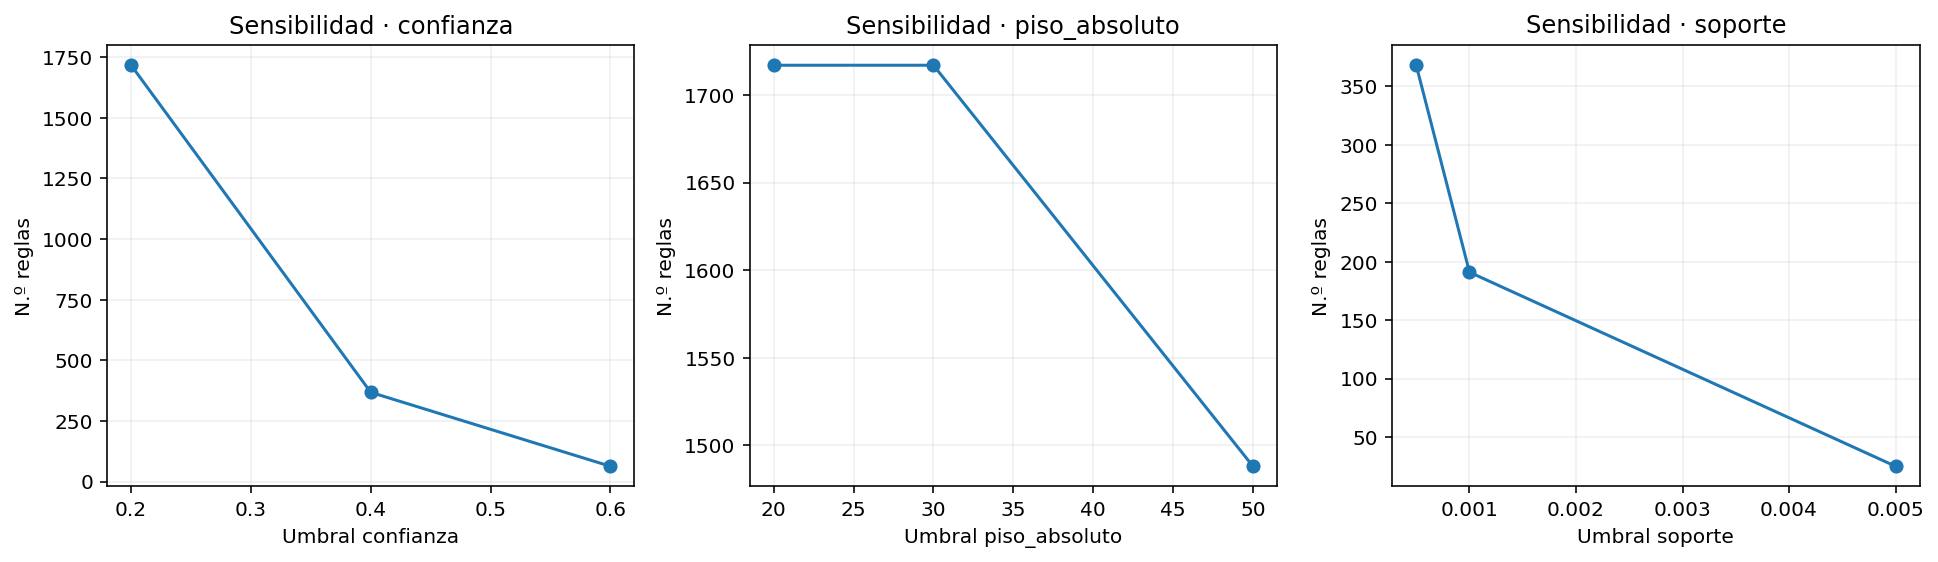

### Jaccard por remuestreo

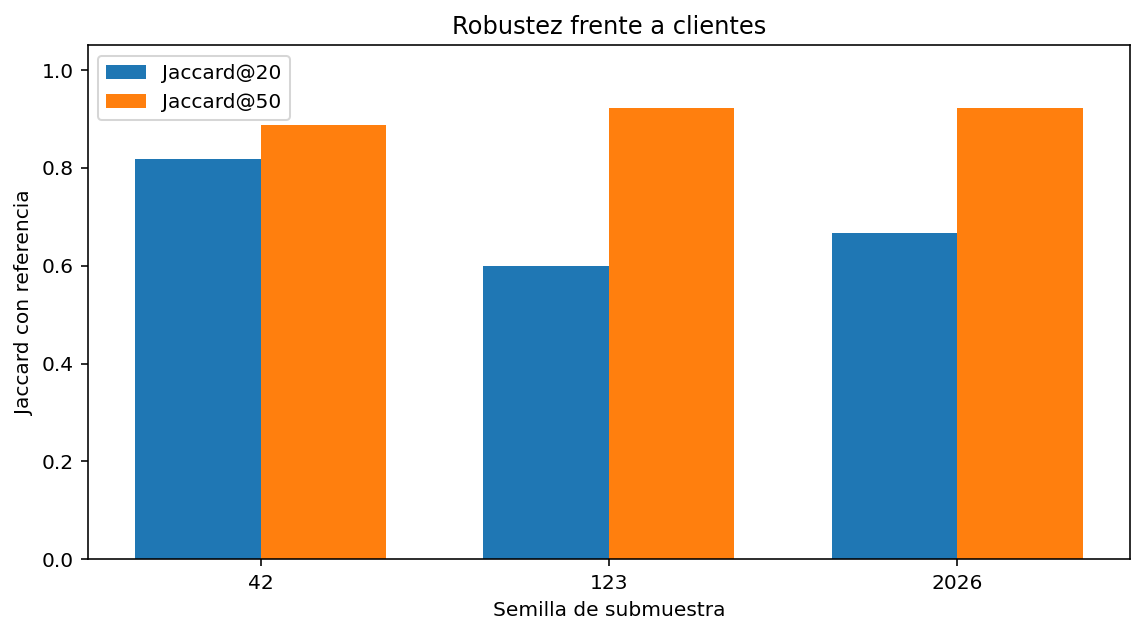

### Persistencia en test

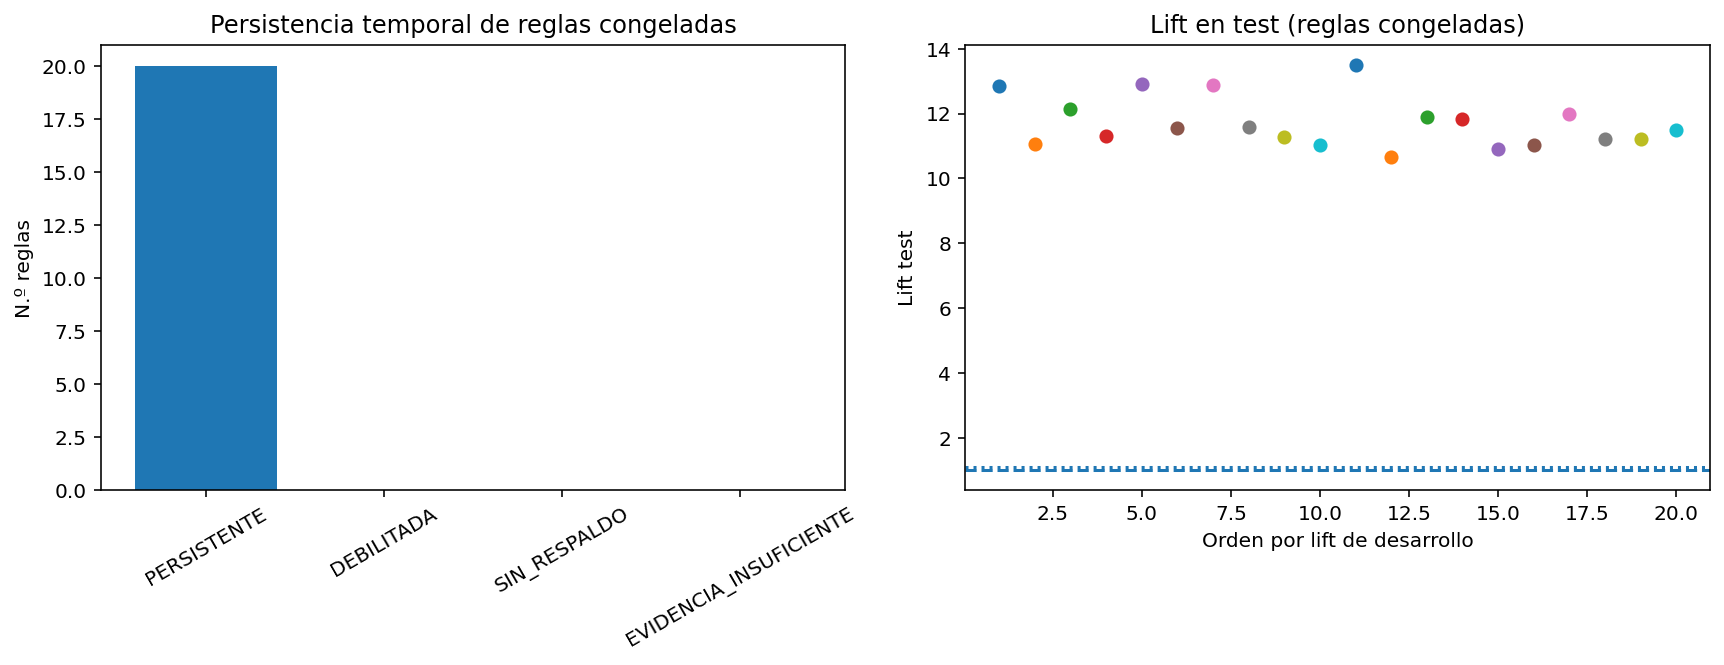

In [13]:
# Galería de resultados: se muestran LAS FIGURAS realmente generadas en la evaluación.
from IPython.display import display, Markdown, Image
from pathlib import Path
import pandas as pd
figuras=[('Sensibilidad de umbrales', 'md2_sensibilidad_umbrales.png'), ('Jaccard por remuestreo', 'md2_estabilidad_jaccard.png'), ('Persistencia en test', 'md2_persistencia_reglas_test.png')]
tablas=[('Apriori frente a FP-Growth', 'md2_comparacion_algoritmos.csv'), ('Sensibilidad de umbrales', 'md2_sensibilidad_umbrales.csv'), ('Robustez de remuestreos', 'md2_estabilidad_remuestreos.csv'), ('Reglas en test', 'md2_fichas_top20.csv'), ('Pilotos de artículos', 'md2_pilotos.csv')]
for titulo, nombre in tablas:
    archivo=OUT/nombre
    if archivo.is_file() and archivo.stat().st_size>10:
        display(Markdown('### '+titulo))
        tabla=pd.read_csv(archivo)
        if len(tabla):display(tabla.head(18).round(4))
    else:display(Markdown(f'**Pendiente:** {titulo} (no se generó {nombre})'))
for titulo,nombre in figuras:
    archivo=OUT/nombre
    if archivo.is_file() and archivo.stat().st_size>100:
        display(Markdown('### '+titulo));display(Image(filename=str(archivo)))
    else: display(Markdown(f'**Figura pendiente:** {titulo}'))


## 9. Validación final y controles de generalización

Revisión de resultados retenidos, sensibilidad y estados P01–P04, sin utilizar test para reoptimizar hiperparámetros.


In [14]:
display(Markdown('**Estado piloto por artículos:** '+str([x for x in PILOTS if x.get('vista')=='article_id'])))

**Estado piloto por artículos:** [{'vista': 'article_id', 'fraccion_clientes': 0.001, 'support': 5e-05, 'nmin': 30, 'N': 8321, 'vacias': 8321, 'items': 0, 'cobertura': 0.0, 'estado': 'SIN_PATRONES_ELEGIBLES', 'itemsets_n': 0, 'segundos': 0.023664007999968817, 'rss_max_bytes': 102346752, 'wall_s': 1.0155204950001462, 'error': 'El proceso terminó, pero no existen itemsets elegibles al umbral fijado'}, {'vista': 'article_id', 'fraccion_clientes': 0.0001, 'support': 5e-05, 'nmin': 30, 'N': 792, 'vacias': 792, 'items': 0, 'cobertura': 0.0, 'estado': 'SIN_PATRONES_ELEGIBLES', 'itemsets_n': 0, 'segundos': 0.005236153000168997, 'rss_max_bytes': 102268928, 'wall_s': 1.0171962120000444, 'error': 'El proceso terminó, pero no existen itemsets elegibles al umbral fijado'}]

## 10. Interpretación científica y limitaciones

Las reglas representan coocurrencias en cestas cliente–día; no representan tickets ni causalidad. Un piloto sin itemsets no queda aprobado.


## 11. Persistencia del modelo y prueba de recarga

Guardar artefactos privados **reutilizables**, probar recarga y distinguir resultados experimentales de refits de uso posterior. No publicar el ZIP privado en GitHub.


In [15]:
# Modelo MD-2 = reglas operativas + itemsets + vocabulario y contrato de cesta.
from pathlib import Path
import json,numpy as np,pandas as pd
from IPython.display import display,Markdown
MD_MODELS=OUT/'modelos';MD_MODELS.mkdir(parents=True,exist_ok=True)
PERSISTENCIA={'objetivo':'MD2','estado':'INCOMPLETO','tipo':'ruleset',
 'aclaracion':'FP-Growth/Apriori descubren reglas; el artefacto reutilizable es el ruleset, no un estimador sklearn'}
if 'MAIN_FI' in globals() and not MAIN_FI.empty and 'MAIN_RULES' in globals() and not MAIN_RULES.empty:
    fi=pd.DataFrame([{'items':'|'.join(sorted(map(str,x))), 'longitud':len(x),'support':float(s)}
         for x,s in zip(MAIN_FI.itemsets,MAIN_FI.support)])
    fi=fi.sort_values(['longitud','items'],kind='stable')
    fi.to_csv(MD_MODELS/'itemsets_frecuentes.csv',index=False)
    cols=['ant','cons','support','confidence','lift','count_xy']
    rules=MAIN_RULES[cols].copy()
    rules.to_csv(MD_MODELS/'reglas_desarrollo.csv',index=False)
    vocab=sorted(str(c) for c in frame.columns)
    contrato={'granularidad':'product_type_name','unidad_cesta':'cliente-dia','periodo_desarrollo_hasta':DEV_LAST,
          'fraccion_clientes':COMPARISON_FRACTION,'n_cestas':int(N),'n_cestas_sin_items':int(meta['vacias']) if isinstance(meta,dict) else None,
          'soporte_minimo_efectivo':float(fmin/N),'piso_absoluto':int(fmin),
          'restricciones_reglas':'max_len 3; consecuente unico; confianza >=0.2; lift > 1',
          'vocabulario':vocab,'n_reglas':len(rules),'n_itemsets':len(fi)}
    (MD_MODELS/'contrato_cestas.json').write_text(json.dumps(contrato,ensure_ascii=False,indent=2),encoding='utf-8')
    # Leer y consultar reglas, sin repetir minería.
    loaded=pd.read_csv(MD_MODELS/'reglas_desarrollo.csv')
    assert len(loaded)==len(MAIN_RULES) and np.allclose(loaded['support'],rules['support'])
    PERSISTENCIA.update(estado='PERSISTIDO_REUTILIZABLE',reglas=len(rules),itemsets=len(fi),
                        verificacion='reglas y soportes coinciden despues de recarga')
else:
    print('PERSISTENCIA INCOMPLETA: no hay itemsets y reglas principales para exportar')
(MD_MODELS/'estado_modelos.json').write_text(json.dumps(PERSISTENCIA,indent=2,ensure_ascii=False),encoding='utf-8')
display(Markdown('**Persistencia MD-2:** '+PERSISTENCIA['estado']))


**Persistencia MD-2:** PERSISTIDO_REUTILIZABLE

## 12. Auditoría y exportación de entregables

Primero se recalcula el inventario; luego se crean **dos ZIP separados** con manifiesto SHA-256 y comprobación de integridad. El notebook ejecutado se guarda por separado desde Kaggle.


In [16]:

# Salida final: todos los estados y evidencias, sin confundir ejecuciones parciales con éxito.
REQUIRED_MD2=['md2_pilotos.csv','md2_comparacion_algoritmos.csv','md2_sensibilidad_umbrales.csv',
              'md2_estabilidad_remuestreos.csv','md2_sensibilidad_cestas.csv',
              'md2_reglas_congeladas_test.csv','md2_control_popularidad_p99.csv','md2_fichas_top20.csv']
missing=[x for x in REQUIRED_MD2 if not (OUT/x).exists()]
save_json({'faltantes':missing,'completo_sin_fallos':len(missing)==0 and all(x['estado'] not in ('FALLO','ERROR','INCOMPLETO','PENDIENTE') for x in STATUS)},'md2_auditoria_entregables.json')
print('MD2: archivos faltantes:',missing)


Guardado: /kaggle/working/hm_modelamiento/md2/md2_auditoria_entregables.json
MD2: archivos faltantes: []


In [17]:
# Exportación única: ZIP de evidencias público-revisable y ZIP de modelos PRIVADO.
# ZIP 1 excluye datos de clientes/Parquet, plantillas con descripciones y pesos binarios.
from pathlib import Path
from IPython.display import display,FileLink,Markdown
import hashlib,json,zipfile,datetime
OBJETIVO='md2'
ROOT=Path('/kaggle/working') if Path('/kaggle/working').is_dir() else OUT.parent.parent
ROOT.mkdir(parents=True,exist_ok=True)
MODEL_DIR=OUT/'modelos'
def sha_file(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(4*2**20),b''):h.update(b)
    return h.hexdigest()
def empaquetar(files,zfile,root,privado):
    manifest={'objetivo':OBJETIVO,'privado':privado,'generado_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
              'archivos':[]}
    with zipfile.ZipFile(zfile,'w',zipfile.ZIP_DEFLATED,compresslevel=3,allowZip64=True) as z:
        for j,p in enumerate(files,1):
            name=str(p.relative_to(root)).replace('\\','/')
            z.write(p,arcname=f'{OBJETIVO}/{name}')
            manifest['archivos'].append({'ruta':name,'tamano_bytes':p.stat().st_size,'sha256':sha_file(p)})
            if j%10==0 or j==len(files):print(f'[ZIP {"MODELOS" if privado else "EVIDENCIAS"}] {j}/{len(files)} archivos',flush=True)
        z.writestr(f'{OBJETIVO}/manifest_exportacion.json',json.dumps(manifest,ensure_ascii=False,indent=2))
    with zipfile.ZipFile(zfile) as check:
        assert check.testzip() is None
        assert f'{OBJETIVO}/manifest_exportacion.json' in check.namelist()
    return manifest
allowed={'.csv','.json','.jsonl','.png','.md','.svg','.txt'}
exclude_names={'referencia_seleccion.csv','referencia_test.csv','md4_consultas_holdout.csv',
               'md4_consultas_ajuste.csv','md2_popularidad_articulos_desarrollo.csv','md4_plantilla_pps_ciega.csv','md4_plantilla_pps_todos_escenarios.csv'}
evidencias=sorted(p for p in OUT.rglob('*') if p.is_file() and not p.is_relative_to(MODEL_DIR)
   and p.suffix.lower() in allowed and p.name not in exclude_names
   and not p.name.startswith('md4_pps_evaluaciones')
   and not any(part in {'cache_ajustes','incidencia','cache','temp','tmp'} for part in p.relative_to(OUT).parts))
modelos=sorted(p for p in MODEL_DIR.rglob('*') if p.is_file()) if MODEL_DIR.exists() else []
zip_e=ROOT/f'HM_{OBJETIVO.upper()}_Evidencias.zip'
zip_m=ROOT/f'HM_{OBJETIVO.upper()}_Modelos_PRIVADO.zip'
man_e=empaquetar(evidencias,zip_e,OUT,False)
man_m=empaquetar(modelos,zip_m,OUT,True)
assert zip_e.exists() and zip_m.exists() and len(man_e['archivos'])>0 and len(man_m['archivos'])>0
print('EVIDENCIAS:',zip_e,round(zip_e.stat().st_size/2**20,2),'MiB')
print('MODELOS PRIVADOS:',zip_m,round(zip_m.stat().st_size/2**20,2),'MiB')
display(Markdown('**Descarga 1 — Evidencias de modelado y evaluación**'))
display(FileLink(str(zip_e)))
display(Markdown('**Descarga 2 — Modelos reutilizables (privado: no publicar en GitHub)**'))
display(FileLink(str(zip_m)))


[ZIP EVIDENCIAS] 10/28 archivos
[ZIP EVIDENCIAS] 20/28 archivos
[ZIP EVIDENCIAS] 28/28 archivos
[ZIP MODELOS] 4/4 archivos
EVIDENCIAS: /kaggle/working/HM_MD2_Evidencias.zip 0.26 MiB
MODELOS PRIVADOS: /kaggle/working/HM_MD2_Modelos_PRIVADO.zip 0.07 MiB


**Descarga 1 — Evidencias de modelado y evaluación**

/kaggle/working/HM_MD2_Evidencias.zip

**Descarga 2 — Modelos reutilizables (privado: no publicar en GitHub)**

/kaggle/working/HM_MD2_Modelos_PRIVADO.zip

## 13. Conclusiones y estado de cierre

Las conclusiones siguientes se generan a partir de los archivos de evaluación y persistencia, no de una declaración estática.


In [18]:
# Cierre ejecutivo derivado de archivos realmente generados.
from IPython.display import display,Markdown
import json
estado_path=OUT/'md2_estado_semana12.json'
eval_state=json.loads(estado_path.read_text()) if estado_path.is_file() else {'estado':'SIN_EVALUACION'}
model_path=OUT/'modelos'/'estado_modelos.json'
mod_state=json.loads(model_path.read_text()) if model_path.is_file() else {'estado':'SIN_PERSISTENCIA'}
pend=[f"{i.get('prueba','?')}: {i.get('estado')}" for i in eval_state.get('pruebas',[])
      if i.get('estado') not in ('PASS','EVALUADO')]
texto=(f'### Resultado final — MD-2\n'
      f'- **Modelado y evaluación:** `{eval_state.get("estado","DESCONOCIDO")}`.\n'
      f'- **Persistencia reutilizable:** `{mod_state.get("estado","DESCONOCIDO")}`.\n'
      f'- **Pruebas con reservas:** {", ".join(pend) if pend else "sin pendientes reportados en el estado automatizado"}.\n'
      f'- **Entregables:** `HM_MD2_Evidencias.zip` y `HM_MD2_Modelos_PRIVADO.zip`.\n'
      '- **Alcance:** las conclusiones deben respetar los protocolos, muestras y particiones declaradas; no hay recalificación retrospectiva con test.\n')
display(Markdown(texto))


### Resultado final — MD-2
- **Modelado y evaluación:** `EVALUACION_INCOMPLETA`.
- **Persistencia reutilizable:** `PERSISTIDO_REUTILIZABLE`.
- **Pruebas con reservas:** MD2-P01: PENDIENTE.
- **Entregables:** `HM_MD2_Evidencias.zip` y `HM_MD2_Modelos_PRIVADO.zip`.
- **Alcance:** las conclusiones deben respetar los protocolos, muestras y particiones declaradas; no hay recalificación retrospectiva con test.
